# Pipeline End-to-End: Detección, Evaluación Post-Isolation Forest, Triage SOC/SRE y Clasificación de Ataques (Octubre 2026)

**Proyecto Reto SAP Monterrey — Cloud Observability & Security**  
**Dataset:** `LOGS_2026_10` en SAP HANA Cloud (`3,748,811` logs | `2026-10-01` a `2026-10-11` UTC)  
**Esquema de Ventaneo:** Ventanas deslizantes de **5 min** con paso de **2.5 min** (`ventanas.py`, sin variables de calendario/horario hábil, manteniendo exactamente la dimensionalidad acordada por el equipo).

---

### Motivación y Arquitectura del Pipeline

El modelo no supervisado `IsolationForest` (`contamination = 0.01`) resuelve la pregunta estadística *"¿Qué ventanas pertenecen al 1% más atípico de la semana?"*, pero **no distingue entre tres fenómenos fundamentalmente distintos**:
1. **[Ruido] Anomalías Comunes (Cola Estadística):** Fluctuaciones puntuales benignas forzadas por la cuota fija del 1% en semanas tranquilas.
2. **[SRE] Incidentes Operativos / Degradación:** Caídas reales de disponibilidad (`HTTP 5xx`, *Circuit Breakers*, picos de *Timeouts* en proveedores LLM) que requieren atención de infraestructura, **no** respuesta de ciberseguridad.
3. **[SOC] Ataques Reales de Seguridad:** Campañas activas de reconocimiento, fuerza bruta, *credential stuffing* distribuido (botnets), escaneo de archivos sensibles (`/.git/config`), movimiento lateral interno o *Prompt Injection*.

Para resolverlo de extremo a extremo en **SAP HANA Cloud + PAL**, este notebook implementa **6 fases**:
1. **Conexión y Particionamiento Semanal en SAP HANA Cloud** (`sap-logs` vs `llm-logs`).
2. **Generación de Ventanas SQL (`5 min / 2.5 min`), Escalado Z-Score (`FeatureNormalizer` PAL) e `IsolationForest` (`contamination=0.01`) + *Event Stitching* (`MAX_GAP=3`).**
3. **Motor de Evaluación Post-IF y Triage en 2 Etapas:**
   - *Etapa 1 (Compuerta de Severidad y Persistencia + Security Override):* Elimina el ruido estadístico del 1% forzoso.
   - *Etapa 2 (Sub-espacios Ortogonales $I_{\text{ataque}}$ vs $I_{\text{operativo}}$ y Taxonomía de Amenazas):* Clasifica cada incidente real en **SOC (con tipo específico de ataque)** vs **SRE (falla operativa)**.
4. **Autopsia Forense SQL en Vivo sobre `LOGS_2026_10`:** Extracción automática de IPs atacantes, rutas objetivo, aplicaciones SAP afectadas y mensajes de evidencia.
5. **Clustering de Amenazas en SAP HANA PAL (`KMeans`) y Validación Matemática:** Similitud Coseno Intra/Inter-Cluster y Coeficiente de Silueta.
6. **Correlación Multi-Ola (*Kill-Chain Campaign Stitching*) y Exportación de Payload JSON para el Agente Forense IA.**

In [1]:
import os
import json
import time
import importlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns

import hana_ml.dataframe as dataframe
from hana_ml.algorithms.pal.preprocessing import FeatureNormalizer, IsolationForest
from hana_ml.algorithms.pal.clustering import KMeans

import ventanas
importlib.reload(ventanas)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 140)
plt.rcParams['figure.dpi'] = 130
sns.set_theme(style='whitegrid', context='notebook')

print("[OK] Librerías y módulo 'ventanas.py' cargados correctamente.")

[OK] Librerías y módulo 'ventanas.py' cargados correctamente.


## 1. Conexión a SAP HANA Cloud y Particionamiento Semanal (`LOGS_2026_10`)

Cargamos credenciales de forma segura desde `.env` / `env (1)` y dividimos el dataset `LOGS_2026_10` en sus dos flujos nativos (`sap-logs%` para **System** y `llm-logs%` para **LLM**) preservando el corte semanal sincronizado (`WEEK_DAYS = 7`, `MIN_LAST_DAYS = 3`).

In [2]:
def cargar_credenciales_hana():
    rutas = ['../.env', '../env (1)', '.env', '../../SAP/env (1)']
    creds = {}
    for r in rutas:
        if os.path.exists(r):
            with open(r, 'r', encoding='utf-8') as f:
                for line in f:
                    line = line.strip()
                    if '=' in line and not line.startswith('#'):
                        k, v = line.split('=', 1)
                        creds[k.strip()] = v.strip().strip('"').strip("'")
            break
    return {
        'address': os.getenv('HANA_ADDRESS', creds.get('HANA_ADDRESS')),
        'port': int(os.getenv('HANA_PORT', creds.get('HANA_PORT', 443))),
        'user': os.getenv('HANA_USER', creds.get('HANA_USER')),
        'password': os.getenv('HANA_PASSWORD', creds.get('HANA_PASSWORD')),
    }

cfg = cargar_credenciales_hana()
conn = dataframe.ConnectionContext(
    address=cfg['address'],
    port=cfg['port'],
    user=cfg['user'],
    password=cfg['password'],
    encrypt=True,
    sslValidateCertificate=False
)
print(f"[CONEXION] Conectado a SAP HANA Cloud ({cfg['address']}): {conn.connection.isconnected()}")

TABLA_OCTUBRE = 'LOGS_2026_10'
dataset = conn.table(TABLA_OCTUBRE).drop(['_IGNORED'])

cols_drop_llm = ['HTTP_STATUS_CODE', 'SERVICE_ID', 'CLIENT_IP']
cols_drop_system = [
    'LLM_ERROR_MESSAGE', 'LLM_RESPONSE_SIZE_BYTES', 'SAP_LLM_RESPONSE_SIZE',
    'SAP_LLM_RESPONSE_TIME', 'LLM_PROMPT_TOKENS', 'LLM_COMPLETION_TOKENS',
    'LLM_TOTAL_TOKENS', 'LLM_RESPONSE_TIME_MS', 'LLM_MODEL_ID', 'LLM_STATUS',
    'LLM_COST_USD', 'LLM_PROMPT_CATEGORY', 'LLM_TEMPERATURE', 'LLM_TOP_P',
    'LLM_STREAM', 'LLM_FINISH_REASON', 'LLM_PROMPT_ID', 'LLM_PROVIDER', 'LLM_PROMPT',
]

df_llm_raw = dataset.filter('''"_INDEX" LIKE 'llm-logs%' ''').drop(cols_drop_llm)
df_system_raw = dataset.filter('''"_INDEX" LIKE 'sap-logs%' ''').drop(cols_drop_system)

WEEK_DAYS = 7
MIN_LAST_DAYS = 3
TS_EXPR = '''TO_TIMESTAMP(REPLACE(REPLACE("TIMESTAMP",'T',' '),'Z',''), 'YYYY-MM-DD HH24:MI:SS.FF3')'''

r_bounds = conn.sql(f'SELECT MIN({TS_EXPR}) AS T0, MAX({TS_EXPR}) AS TMAX, COUNT(*) AS TOTAL FROM "{TABLA_OCTUBRE}"').collect()
t0 = pd.to_datetime(r_bounds.loc[0, 'T0'])
t_max = pd.to_datetime(r_bounds.loc[0, 'TMAX'])
total_logs = int(r_bounds.loc[0, 'TOTAL'])

span = t_max - t0
n_full = span // pd.Timedelta(days=WEEK_DAYS)
rest = span - n_full * pd.Timedelta(days=WEEK_DAYS)
n_weeks = int(n_full + (1 if rest >= pd.Timedelta(days=MIN_LAST_DAYS) else 0))

t0_sql = t0.strftime('%Y-%m-%d %H:%M:%S')
week_expr = (f"FLOOR(SECONDS_BETWEEN(TO_TIMESTAMP('{t0_sql}','YYYY-MM-DD HH24:MI:SS'), "
             f"{TS_EXPR}) / {WEEK_DAYS * 86400})")

df_system = df_system_raw.select('*', (week_expr, 'WEEK_IDX'))
df_llm = df_llm_raw.select('*', (week_expr, 'WEEK_IDX'))

system_weeks = {w: df_system.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}
llm_weeks = {w: df_llm.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}

print(f"[INFO] Rango temporal: {t0} -> {t_max} UTC | Total registros: {total_logs:,} | Batches semanales: {n_weeks}")
for w in range(n_weeks):
    print(f"   • Semana {w}: System = {system_weeks[w].count():,} logs | LLM = {llm_weeks[w].count():,} logs")

[CONEXION] Conectado a SAP HANA Cloud (0e62b977-38ea-48bd-b34a-72acf111006d.hna0.prod-us10.hanacloud.ondemand.com): True
[INFO] Rango temporal: 2026-10-01 00:00:00 -> 2026-10-11 23:59:59 UTC | Total registros: 3,748,811 | Batches semanales: 2
   • Semana 0: System = 1,441,821 logs | LLM = 959,153 logs
   • Semana 1: System = 809,290 logs | LLM = 538,547 logs


## 2. Ventaneo Deslizante (5 min / 2.5 min), Escalado Previo (`FeatureNormalizer`) e `IsolationForest`

Mantenemos intacto el motor `ventanas.py` (ventanas de **5 min** con traslape de **2.5 min**) y aplicamos las mejores prácticas en **SAP HANA PAL**:
- **Pre-escalado Z-Score (`FeatureNormalizer`):** Estandariza media 0 y desviación estándar 1 por batch semanal antes de entrenar el modelo.
- **Detección con `IsolationForest` (`n_estimators=250, max_samples=256, contamination=0.01`):** Conservamos tanto el `SCORE` continuo de aislamiento como las variables originales (incluyendo `NOVEL_IPS` y `NOVEL_PATHS` generadas por `ventanas.py` para el perfilado forense posterior).
- **Stitching inicial de eventos (`MAX_GAP = 3`):** Agrupa ventanas anómalas separadas por $\le 3$ índices ($\le 7.5$ min) dentro de cada semana.

In [3]:
FEATURES_SYSTEM = [
    'TOTAL_REQUESTS', 'REQUEST_RATE_STD', 'INTERVAL_CV',
    'UNIQUE_IPS_COUNT', 'IP_ENTROPY', 'IP_TOP_SHARE',
    'ERROR_RATE_400', 'ERROR_RATE_500', 'NON_200_RATE',
    'RATIO_ERROR', 'RATIO_WARN', 'RATIO_SECURITY', 'RATIO_INFO', 'RATIO_AUDIT',
    'GET_VS_POST_RATIO',
    'JS_HTTP_STATUS_CODE', 'JS_HEADERS_HTTP_REQUEST_METHOD', 'JS_SAP_FUNCTION_LOG_TYPE',
    'JS_HEATHERS_REQUEST_PATH', 'JS_SAP_FUNCTION_APPLICATION', 'JS_SAP_SOURCE_TYPE',
    'JS_SAP_APP_ENV', 'JS_REGION_CODE', 'JS_HEADERS_CONTENT_TYPE',
]

FEATURES_LLM = [
    'TOTAL_LLM_REQUESTS', 'AVG_LLM_COST_USD', 'RATIO_INJECTION', 'AVG_TOKEN_RATIO',
    'AVG_RESPONSE_TIME_MS', 'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE', 'TEMPERATURE_VARIANCE',
    'PROMPT_CATEGORY_ENTROPY', 'STREAM_RATIO', 'AVG_PROMPT_LENGTH', 'MAX_PROMPT_LENGTH',
]

MAX_GAP = {'system': 3, 'llm': 3}

def ejecutar_if_con_escalado(win_hana, features, contamination=0.01):
    """Escala con FeatureNormalizer (Z-Score) en HANA PAL y ejecuta IsolationForest."""
    scaler = FeatureNormalizer(
        method='z-score',
        z_score_method='mean-standard',
        division_by_zero_handler='ignore'
    )
    win_scaled = scaler.fit_transform(data=win_hana, key='WINDOW_INDEX', features=features)

    model = IsolationForest(n_estimators=250, max_samples=256, random_state=42)
    model.fit(data=win_scaled, key='WINDOW_INDEX', features=features)
    pred = model.predict(
        data=win_scaled,
        key='WINDOW_INDEX',
        features=features,
        contamination=contamination,
        show_explainer=False
    )
    df_win = win_hana.collect()
    df_pred = pred.collect()
    return df_win.merge(df_pred, on='WINDOW_INDEX').sort_values('WINDOW_INDEX').reset_index(drop=True)

def agrupar_eventos(df_res, max_gap=3):
    df_res = df_res.sort_values(['WEEK', 'WINDOW_INDEX']).reset_index(drop=True)
    anom = df_res[df_res['LABEL'] == -1]
    gap = anom.groupby('WEEK')['WINDOW_INDEX'].diff()
    df_res['EVENTO_ID'] = pd.NA
    df_res.loc[anom.index, 'EVENTO_ID'] = ((gap.isna()) | (gap > max_gap)).cumsum().astype(int)
    return df_res

t_if = time.time()
res_batches = {'system': [], 'llm': []}

for w in range(n_weeks):
    t_w = time.time()
    win_sys = ventanas.materialize(conn, ventanas.build_system_windows(conn, system_weeks[w], df_system), '#WIN_SYSTEM')
    win_llm = ventanas.materialize(conn, ventanas.build_llm_windows(conn, llm_weeks[w]), '#WIN_LLM')

    r_sys = ejecutar_if_con_escalado(win_sys, FEATURES_SYSTEM, contamination=0.01)
    r_sys.insert(0, 'WEEK', w)
    res_batches['system'].append(r_sys)

    r_llm = ejecutar_if_con_escalado(win_llm, FEATURES_LLM, contamination=0.01)
    r_llm.insert(0, 'WEEK', w)
    res_batches['llm'].append(r_llm)
    print(f"  [OK] Semana {w} procesada en {time.time() - t_w:.1f} s | Ventanas System={len(r_sys):,}, LLM={len(r_llm):,}")

if_system = agrupar_eventos(pd.concat(res_batches['system'], ignore_index=True), MAX_GAP['system'])
if_llm = agrupar_eventos(pd.concat(res_batches['llm'], ignore_index=True), MAX_GAP['llm'])
if_system['WINDOW_START'] = pd.to_datetime(if_system['WINDOW_START'])
if_llm['WINDOW_START'] = pd.to_datetime(if_llm['WINDOW_START'])

print(f"\n[TIEMPO] Pipeline PAL finalizado en {time.time() - t_if:.1f} s")
print(f"[RESUMEN] Salida cruda IF -> System: {(if_system['LABEL']==-1).sum()} ventanas anómalas en {if_system['EVENTO_ID'].nunique()} eventos")
print(f"[RESUMEN] Salida cruda IF -> LLM:    {(if_llm['LABEL']==-1).sum()} ventanas anómalas en {if_llm['EVENTO_ID'].nunique()} eventos")

  [OK] Semana 0 procesada en 89.9 s | Ventanas System=4,031, LLM=4,031
  [OK] Semana 1 procesada en 48.3 s | Ventanas System=2,303, LLM=2,303

[TIEMPO] Pipeline PAL finalizado en 138.2 s
[RESUMEN] Salida cruda IF -> System: 65 ventanas anómalas en 14 eventos
[RESUMEN] Salida cruda IF -> LLM:    65 ventanas anómalas en 59 eventos


## 3. Motor de Evaluación Post-Isolation Forest: Separación de *Anomalías Comunes*, *Fallas SRE* y *Ataques Reales*

### Fundamentación Matemática del Triage en 2 Etapas

Para cada ventana $t$ de la semana $w$, calculamos primero su vector de estandarización robusta respecto a las ventanas **normales** (`LABEL == 1`) de su propia semana:

$$Z_{t, j} = \frac{X_{t, j} - \mu_{w, j}^{(\text{norm})}}{\sigma_{w, j}^{(\text{norm})}}$$

Luego evaluamos cada evento agrupado $E$ mediante dos etapas secuenciales:

1. **Etapa 1 — Compuerta Estructural (*Noise Gate*):** Filtra las colas estadísticas normales producidas por la cuota fija del 1%:
   - **Severidad de aislamiento:** $\text{SCORE\_PICO}(E) \ge 0.58$, **O**
   - **Persistencia temporal:** $N_{\text{ventanas}}(E) \ge 2$ ($\ge 5–7.5$ min sostenidos), **O**
   - **Excepción de Seguridad Crítica (*Security Override*):** Pico extremo ($Z \ge 4.0$) en indicadores directos de compromiso (`RATIO_SECURITY` o `NOVEL_PATHS` en System; `RATIO_INJECTION` en LLM) para no descartar ataques intensos de corta duración.
   - *Si no cumple ninguno, se clasifica como **`[Ruido] Anomalía Común (Cola Estadística)`**.*

2. **Etapa 2 — Índice de Firma Maliciosa ($I_{\text{ataque}}$) vs. Firma Operativa ($I_{\text{operativo}}$) y Taxonomía de Ataque:**
   - En **System**:
     - $I_{\text{ataque}} = \text{mean\_top3}\big(Z^+_{\text{RATIO\_SECURITY}}, Z^+_{\text{ERROR\_RATE\_400}}, Z^+_{\text{IP\_TOP\_SHARE}}, Z^+_{\text{UNIQUE\_IPS}}, Z^+_{\text{JS\_PATH}}, Z^+_{\text{NOVEL\_PATHS}}\big)$
     - $I_{\text{operativo}} = \frac{1}{2}\big(Z^+_{\text{ERROR\_RATE\_500}} + Z^+_{\text{RATIO\_ERROR}}\big)$
     - Si $I_{\text{operativo}} > I_{\text{ataque}}$ y $Z_{\text{RATIO\_SECURITY}} < 1.0$: **`[SRE] Incidente Operativo`** (*Caída 5xx / Circuit Breaker*). De lo contrario: **`[SOC] Ataque Confirmado`** con asignación automática del vector de ataque (Botnet Distribuido, Escaneo Web Crítico, Fuerza Bruta/Intrusión Auth o Reconocimiento/Fuzzing 1-IP).
   - En **LLM**:
     - Contrasta $I_{\text{ataque}} = Z^+_{\text{RATIO\_INJECTION}}$ contra $I_{\text{operativo}} = \max(Z^+_{\text{LLM\_TIMEOUT\_RATE}}, Z^+_{\text{AVG\_RESPONSE\_TIME\_MS}}, Z^+_{\text{LLM\_ERROR\_RATE}})$, separando **Ráfagas de Prompt Injection (`[SOC]`)** de **Cuellos de Botella / Timeouts del Proveedor (`[SRE]`)**.

In [4]:
SYS_ALL_ANALYTIC_COLS = FEATURES_SYSTEM + ['NOVEL_IPS', 'NOVEL_PATHS']

def agregar_zscores_semanales(df, cols):
    """Calcula Z-scores por columna usando únicamente la media y std de ventanas normales (LABEL==1) de cada semana."""
    df_out = df.copy()
    for c in cols:
        df_out[f'Z_{c}'] = 0.0
    for w, grp in df_out.groupby('WEEK'):
        norm = grp[grp['LABEL'] == 1]
        mu = norm[cols].mean()
        sd = norm[cols].std(ddof=0).replace(0, 1.0)
        z_vals = (grp[cols] - mu) / sd
        for c in cols:
            df_out.loc[grp.index, f'Z_{c}'] = z_vals[c]
    return df_out

if_system = agregar_zscores_semanales(if_system, SYS_ALL_ANALYTIC_COLS)
if_llm = agregar_zscores_semanales(if_llm, FEATURES_LLM)

def pos(x):
    return max(0.0, float(x))

def cpos(x, cap=12.0):
    return min(max(0.0, float(x)), cap)

def evaluar_eventos_system(df_sys, score_thr=0.58, z_override_thr=5.0):
    anom = df_sys[df_sys['LABEL'] == -1].copy()
    registros = []
    for eid, g in anom.groupby('EVENTO_ID'):
        idx_pico = g['SCORE'].idxmax()
        p = g.loc[idx_pico]
        n_win = len(g)
        dur_min = (g['WINDOW_START'].max() - g['WINDOW_START'].min()).total_seconds() / 60.0 + 5.0
        score_pico = float(p['SCORE'])

        # Perfil Z-score en la ventana pico del evento (alineado con Heatmap y Clustering PAL)
        z_sec = float(p['Z_RATIO_SECURITY'])
        z_400 = float(p['Z_ERROR_RATE_400'])
        z_500 = float(p['Z_ERROR_RATE_500'])
        z_err = float(p['Z_RATIO_ERROR'])
        z_aud = float(p['Z_RATIO_AUDIT'])
        z_ip_share = float(p['Z_IP_TOP_SHARE'])
        z_uips = float(p['Z_UNIQUE_IPS_COUNT'])
        z_jspath = float(p['Z_JS_HEATHERS_REQUEST_PATH'])
        z_novel_p = float(p['Z_NOVEL_PATHS'])
        novel_paths_sum = int(g['NOVEL_PATHS'].max())
        novel_ips_sum = int(g['NOVEL_IPS'].max())

        # Señal de botnet distribuida: aumento de IPs únicas acompañado de rechazos 4xx o alertas SECURITY
        z_botnet_auth = cpos(z_uips) if (z_400 >= 1.0 or z_sec >= 1.0) else 0.0
        z_path_atk = cpos(z_jspath) if (z_400 >= 1.0 or z_sec >= 1.0 or z_ip_share >= 2.0) else 0.0

        # Sub-espacios acotados [0..12σ] para comparabilidad simétrica SOC vs SRE
        atk_signals = sorted([
            cpos(z_sec), cpos(z_400), cpos(z_ip_share),
            z_botnet_auth, z_path_atk, cpos(z_novel_p)
        ], reverse=True)
        idx_ataque = float(np.mean(atk_signals[:3]))
        idx_operativo = float(0.55 * cpos(z_500) + 0.45 * cpos(z_err))

        # Etapa 1: Compuerta estructural (separa ruido del 1% forzoso vs incidentes reales)
        pasa_score = score_pico >= score_thr
        pasa_persistencia = n_win >= 3
        pasa_override = (z_sec >= z_override_thr) or (novel_paths_sum >= 5)

        if not (pasa_score or pasa_persistencia or pasa_override):
            categoria = '[Ruido] Anomalía Común'
            subtipo = 'Variación Estadística Benigna (Cuota 1% IF)'
            severidad = 'BAJA (Descartada)'
        else:
            # Etapa 2: Separación SRE vs SOC y firma específica
            if idx_operativo > idx_ataque and z_sec < 1.5 and cpos(z_500) >= 3.0:
                categoria = '[SRE] Incidente Operativo'
                subtipo = 'Caída de Disponibilidad / Tormenta HTTP 5xx (Circuit Breaker)'
                severidad = 'ALTA (SRE)'
            else:
                categoria = '[SOC] Ataque Confirmado'
                ip_share_max = float(g['IP_TOP_SHARE'].max())
                get_ratio_min = float(g['GET_VS_POST_RATIO'].min())
                if z_botnet_auth >= 2.5 and ip_share_max < 0.06:
                    subtipo = 'Credential Stuffing / Password Spraying Distribuido (Botnet)'
                elif novel_paths_sum >= 3 or ip_share_max >= 0.30:
                    subtipo = 'Escaneo Agresivo de Vulnerabilidades Web y Rutas Críticas'
                elif ip_share_max >= 0.10 and (get_ratio_min < 0.22 or z_aud >= 1.8):
                    subtipo = 'Fuerza Bruta en Login / Intrusión y Escalada de Privilegios'
                else:
                    subtipo = 'Reconocimiento Activo / Enumeración BAPI-REST (1-IP)'
                severidad = 'CRÍTICA (SOC)' if (score_pico >= 0.75 or n_win >= 8) else 'ALTA (SOC)'

        z_cols = {c: float(p[f'Z_{c}']) for c in SYS_ALL_ANALYTIC_COLS}
        top3 = sorted(z_cols.items(), key=lambda kv: abs(kv[1]), reverse=True)[:3]
        drivers_txt = ', '.join([f"{k} ({v:+.1f}σ)" for k, v in top3])

        registros.append({
            'STREAM': 'SYSTEM',
            'EVENTO_ID': int(eid),
            'WEEK': int(p['WEEK']),
            'INICIO': g['WINDOW_START'].min(),
            'FIN': g['WINDOW_START'].max() + pd.Timedelta(minutes=5),
            'VENTANA_PICO': p['WINDOW_START'],
            'N_VENTANAS': n_win,
            'DURACION_MIN': dur_min,
            'SCORE_PICO': round(score_pico, 4),
            'IDX_ATAQUE': round(idx_ataque, 2),
            'IDX_OPERATIVO': round(idx_operativo, 2),
            'CATEGORIA_TRIAGE': categoria,
            'TIPO_ESPECIFICO': subtipo,
            'SEVERIDAD': severidad,
            'REQS_PICO': int(p['TOTAL_REQUESTS']),
            'RATIO_SEC_PICO': round(float(p['RATIO_SECURITY']), 3),
            'ERR_400_PICO': round(float(p['ERROR_RATE_400']), 3),
            'ERR_500_PICO': round(float(p['ERROR_RATE_500']), 3),
            'UNIQUE_IPS_PICO': int(p['UNIQUE_IPS_COUNT']),
            'IP_TOP_SHARE_PICO': round(float(p['IP_TOP_SHARE']), 3),
            'NOVEL_PATHS_MAX': novel_paths_sum,
            'NOVEL_IPS_MAX': novel_ips_sum,
            'TOP_DRIVERS_Z': drivers_txt,
        })
    return pd.DataFrame(registros)

def evaluar_eventos_llm(df_l, score_thr=0.58, z_inj_override=4.0):
    anom = df_l[df_l['LABEL'] == -1].copy()
    registros = []
    for eid, g in anom.groupby('EVENTO_ID'):
        idx_pico = g['SCORE'].idxmax()
        p = g.loc[idx_pico]
        n_win = len(g)
        dur_min = (g['WINDOW_START'].max() - g['WINDOW_START'].min()).total_seconds() / 60.0 + 5.0
        score_pico = float(p['SCORE'])

        z_inj = float(g['Z_RATIO_INJECTION'].max())
        z_tmo = float(g['Z_LLM_TIMEOUT_RATE'].max())
        z_lat = float(g['Z_AVG_RESPONSE_TIME_MS'].max())
        z_err = float(g['Z_LLM_ERROR_RATE'].max())

        idx_ataque = cpos(z_inj)
        idx_operativo = float(np.mean(sorted([cpos(z_tmo), cpos(z_lat), cpos(z_err)], reverse=True)[:2]))

        pasa_score = score_pico >= score_thr
        pasa_persistencia = n_win >= 2
        pasa_override = z_inj >= z_inj_override

        if not (pasa_score or pasa_persistencia or pasa_override):
            categoria = '[Ruido] Anomalía Común'
            subtipo = 'Fluctuación Binomial Benigna (Tokens / Temperatura / Cola 1%)'
            severidad = 'BAJA (Descartada)'
        else:
            if z_inj >= z_inj_override and idx_ataque >= idx_operativo:
                categoria = '[SOC] Ataque Confirmado'
                subtipo = 'Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado'
                severidad = 'ALTA (SOC-LLM)'
            else:
                categoria = '[SRE] Incidente Operativo'
                if pos(z_tmo) >= 2.2 or pos(z_lat) >= 2.2:
                    subtipo = 'Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM'
                else:
                    subtipo = 'Pico Transitorio de Errores de API / Gateway LLM'
                severidad = 'MEDIA (SRE-LLM)'

        z_cols = {c: float(p[f'Z_{c}']) for c in FEATURES_LLM}
        top3 = sorted(z_cols.items(), key=lambda kv: abs(kv[1]), reverse=True)[:3]
        drivers_txt = ', '.join([f"{k} ({v:+.1f}σ)" for k, v in top3])

        registros.append({
            'STREAM': 'LLM',
            'EVENTO_ID': int(eid),
            'WEEK': int(p['WEEK']),
            'INICIO': g['WINDOW_START'].min(),
            'FIN': g['WINDOW_START'].max() + pd.Timedelta(minutes=5),
            'VENTANA_PICO': p['WINDOW_START'],
            'N_VENTANAS': n_win,
            'DURACION_MIN': dur_min,
            'SCORE_PICO': round(score_pico, 4),
            'IDX_ATAQUE': round(idx_ataque, 2),
            'IDX_OPERATIVO': round(idx_operativo, 2),
            'CATEGORIA_TRIAGE': categoria,
            'TIPO_ESPECIFICO': subtipo,
            'SEVERIDAD': severidad,
            'REQS_PICO': int(p['TOTAL_LLM_REQUESTS']),
            'RATIO_INJ_PICO': round(float(p['RATIO_INJECTION']), 4),
            'TIMEOUT_PICO': round(float(p['LLM_TIMEOUT_RATE']), 3),
            'ERROR_PICO': round(float(p['LLM_ERROR_RATE']), 3),
            'RESP_MS_PICO': round(float(p['AVG_RESPONSE_TIME_MS']), 1),
            'TOP_DRIVERS_Z': drivers_txt,
        })
    return pd.DataFrame(registros)

ev_sys = evaluar_eventos_system(if_system)
ev_llm = evaluar_eventos_llm(if_llm)

# Propagar la categoría de cada evento de vuelta a las ventanas para graficar con semáforo
if_system = if_system.merge(ev_sys[['EVENTO_ID', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO']], on='EVENTO_ID', how='left')
if_llm = if_llm.merge(ev_llm[['EVENTO_ID', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO']], on='EVENTO_ID', how='left')

resumen_funnel = pd.concat([
    ev_sys.groupby('CATEGORIA_TRIAGE').agg(EVENTOS=('EVENTO_ID', 'count'), VENTANAS=('N_VENTANAS', 'sum')).assign(STREAM='SYSTEM'),
    ev_llm.groupby('CATEGORIA_TRIAGE').agg(EVENTOS=('EVENTO_ID', 'count'), VENTANAS=('N_VENTANAS', 'sum')).assign(STREAM='LLM')
]).reset_index()[['STREAM', 'CATEGORIA_TRIAGE', 'EVENTOS', 'VENTANAS']]

print("[TRIAGE] EMBUDO DE EVALUACIÓN POST-ISOLATION FOREST (REDUCCIÓN DE FATIGA DE ALERTAS):")
display(resumen_funnel)

print("\n[DETALLE] DETALLE COMPLETO DE LOS 14 EVENTOS DE SYSTEM CLASIFICADOS:")
cols_show_sys = ['EVENTO_ID', 'VENTANA_PICO', 'N_VENTANAS', 'SCORE_PICO', 'IDX_ATAQUE', 'IDX_OPERATIVO', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO']
display(ev_sys[cols_show_sys])

print("\n[DETALLE] INCIDENTES REALES FILTRADOS EN LLM (DESCARTANDO LAS COLAS BENIGNAS DEL 1%):")
cols_show_llm = ['EVENTO_ID', 'VENTANA_PICO', 'N_VENTANAS', 'SCORE_PICO', 'IDX_ATAQUE', 'IDX_OPERATIVO', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO', 'TOP_DRIVERS_Z']
display(ev_llm[ev_llm['CATEGORIA_TRIAGE'] != '[Ruido] Anomalía Común'][cols_show_llm])

[TRIAGE] EMBUDO DE EVALUACIÓN POST-ISOLATION FOREST (REDUCCIÓN DE FATIGA DE ALERTAS):


,STREAM,CATEGORIA_TRIAGE,EVENTOS,VENTANAS
0,SYSTEM,[Ruido] Anomalía Común,7,8
1,SYSTEM,[SOC] Ataque Confirmado,6,49
2,SYSTEM,[SRE] Incidente Operativo,1,8
3,LLM,[Ruido] Anomalía Común,50,50
4,LLM,[SOC] Ataque Confirmado,4,4
5,LLM,[SRE] Incidente Operativo,5,11



[DETALLE] DETALLE COMPLETO DE LOS 14 EVENTOS DE SYSTEM CLASIFICADOS:


,EVENTO_ID,VENTANA_PICO,N_VENTANAS,SCORE_PICO,IDX_ATAQUE,IDX_OPERATIVO,CATEGORIA_TRIAGE,TIPO_ESPECIFICO
0,1,2026-10-01 07:57:30,1,0.5672,1.32,0.04,[Ruido] Anomalía Común,Variación Estadística Benigna (Cuota 1% IF)
1,2,2026-10-01 09:35:00,5,0.7701,11.15,0.93,[SOC] Ataque Confirmado,Reconocimiento Activo / Enumeración BAPI-REST (1-IP)
2,3,2026-10-01 12:47:30,7,0.8007,12.00,0.00,[SOC] Ataque Confirmado,Fuerza Bruta en Login / Intrusión y Escalada de Privilegios
3,4,2026-10-01 23:57:30,8,0.7025,0.00,8.42,[SRE] Incidente Operativo,Caída de Disponibilidad / Tormenta HTTP 5xx (Circuit Breaker)
4,5,2026-10-04 10:22:30,2,0.5317,1.19,2.68,[Ruido] Anomalía Común,Variación Estadística Benigna (Cuota 1% IF)
5,6,2026-10-04 10:37:30,1,0.5219,0.19,2.09,[Ruido] Anomalía Común,Variación Estadística Benigna (Cuota 1% IF)
6,7,2026-10-04 19:47:30,1,0.5269,1.33,0.87,[Ruido] Anomalía Común,Variación Estadística Benigna (Cuota 1% IF)
7,8,2026-10-05 02:40:00,1,0.5396,2.09,0.06,[Ruido] Anomalía Común,Variación Estadística Benigna (Cuota 1% IF)
8,9,2026-10-05 13:07:30,14,0.8131,12.00,1.84,[SOC] Ataque Confirmado,Escaneo Agresivo de Vulnerabilidades Web y Rutas Críticas
9,10,2026-10-05 23:17:30,1,0.5176,0.27,0.00,[Ruido] Anomalía Común,Variación Estadística Benigna (Cuota 1% IF)



[DETALLE] INCIDENTES REALES FILTRADOS EN LLM (DESCARTANDO LAS COLAS BENIGNAS DEL 1%):


,EVENTO_ID,VENTANA_PICO,N_VENTANAS,SCORE_PICO,IDX_ATAQUE,IDX_OPERATIVO,CATEGORIA_TRIAGE,TIPO_ESPECIFICO,TOP_DRIVERS_Z
6,7,2026-10-02 02:35:00,1,0.5447,4.13,1.41,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,"RATIO_INJECTION (+4.1σ), AVG_TOKEN_RATIO (+2.7σ), LLM_ERROR_RATE (+1.7σ)"
13,14,2026-10-03 07:25:00,2,0.5424,0.12,3.96,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,"LLM_TIMEOUT_RATE (+3.9σ), AVG_RESPONSE_TIME_MS (+2.8σ), MAX_PROMPT_LENGTH (-1.9σ)"
14,15,2026-10-03 12:27:30,1,0.5532,4.86,0.87,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,"RATIO_INJECTION (+4.9σ), LLM_TIMEOUT_RATE (-2.0σ), AVG_RESPONSE_TIME_MS (-1.9σ)"
15,16,2026-10-03 13:50:00,1,0.5408,4.27,1.68,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,"RATIO_INJECTION (+4.3σ), AVG_TOKEN_RATIO (+2.4σ), TEMPERATURE_VARIANCE (-1.8σ)"
17,18,2026-10-04 04:30:00,2,0.5436,1.34,1.55,[SRE] Incidente Operativo,Pico Transitorio de Errores de API / Gateway LLM,"LLM_ERROR_RATE (+3.1σ), TOTAL_LLM_REQUESTS (-1.9σ), AVG_LLM_COST_USD (-1.9σ)"
24,25,2026-10-05 19:30:00,1,0.5294,6.21,1.42,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,"RATIO_INJECTION (+6.2σ), PROMPT_CATEGORY_ENTROPY (-2.2σ), TOTAL_LLM_REQUESTS (-1.7σ)"
27,28,2026-10-06 06:55:00,2,0.5467,0.26,5.16,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,"AVG_RESPONSE_TIME_MS (+5.6σ), LLM_TIMEOUT_RATE (+4.7σ), TOTAL_LLM_REQUESTS (-1.4σ)"
36,37,2026-10-07 23:10:00,2,0.5453,3.21,3.93,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,"LLM_TIMEOUT_RATE (+3.9σ), AVG_RESPONSE_TIME_MS (+3.9σ), RATIO_INJECTION (+3.2σ)"
49,50,2026-10-10 08:17:30,3,0.5472,0.00,3.17,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,"AVG_RESPONSE_TIME_MS (+3.1σ), LLM_ERROR_RATE (-2.3σ), LLM_TIMEOUT_RATE (+2.3σ)"


## 4. Diagnóstico Visual del Triage: Series de Tiempo, Compuerta de Ruido y Plano SOC vs. SRE

Generamos tres visualizaciones complementarias para justificar ante negocio y equipo técnico cómo trabaja la capa de evaluación post-IF:
1. **Series de Tiempo con Semáforo de Triage:** Compara visualmente los ataques reales (`[SOC]`), incidentes operativos (`[SRE]`) y las anomalías comunes descartadas (`[Ruido]`).
2. **Compuerta Estructural (`N_VENTANAS` vs `SCORE_PICO`):** Demuestra la brecha bimodal exacta en System (`0.52–0.54` vs `0.62–0.81`) y por qué en LLM casi todas las banderas caen debajo de `0.57` salvo ráfagas puntuales de inyección o cuellos de botella de latencia.
3. **Plano Ortogonal de Firmas ($I_{\text{operativo}}$ vs $I_{\text{ataque}}$):** Ilustra cómo se desacoplan matemáticamente las caídas `5xx` / *Timeouts* de las intrusiones reales.

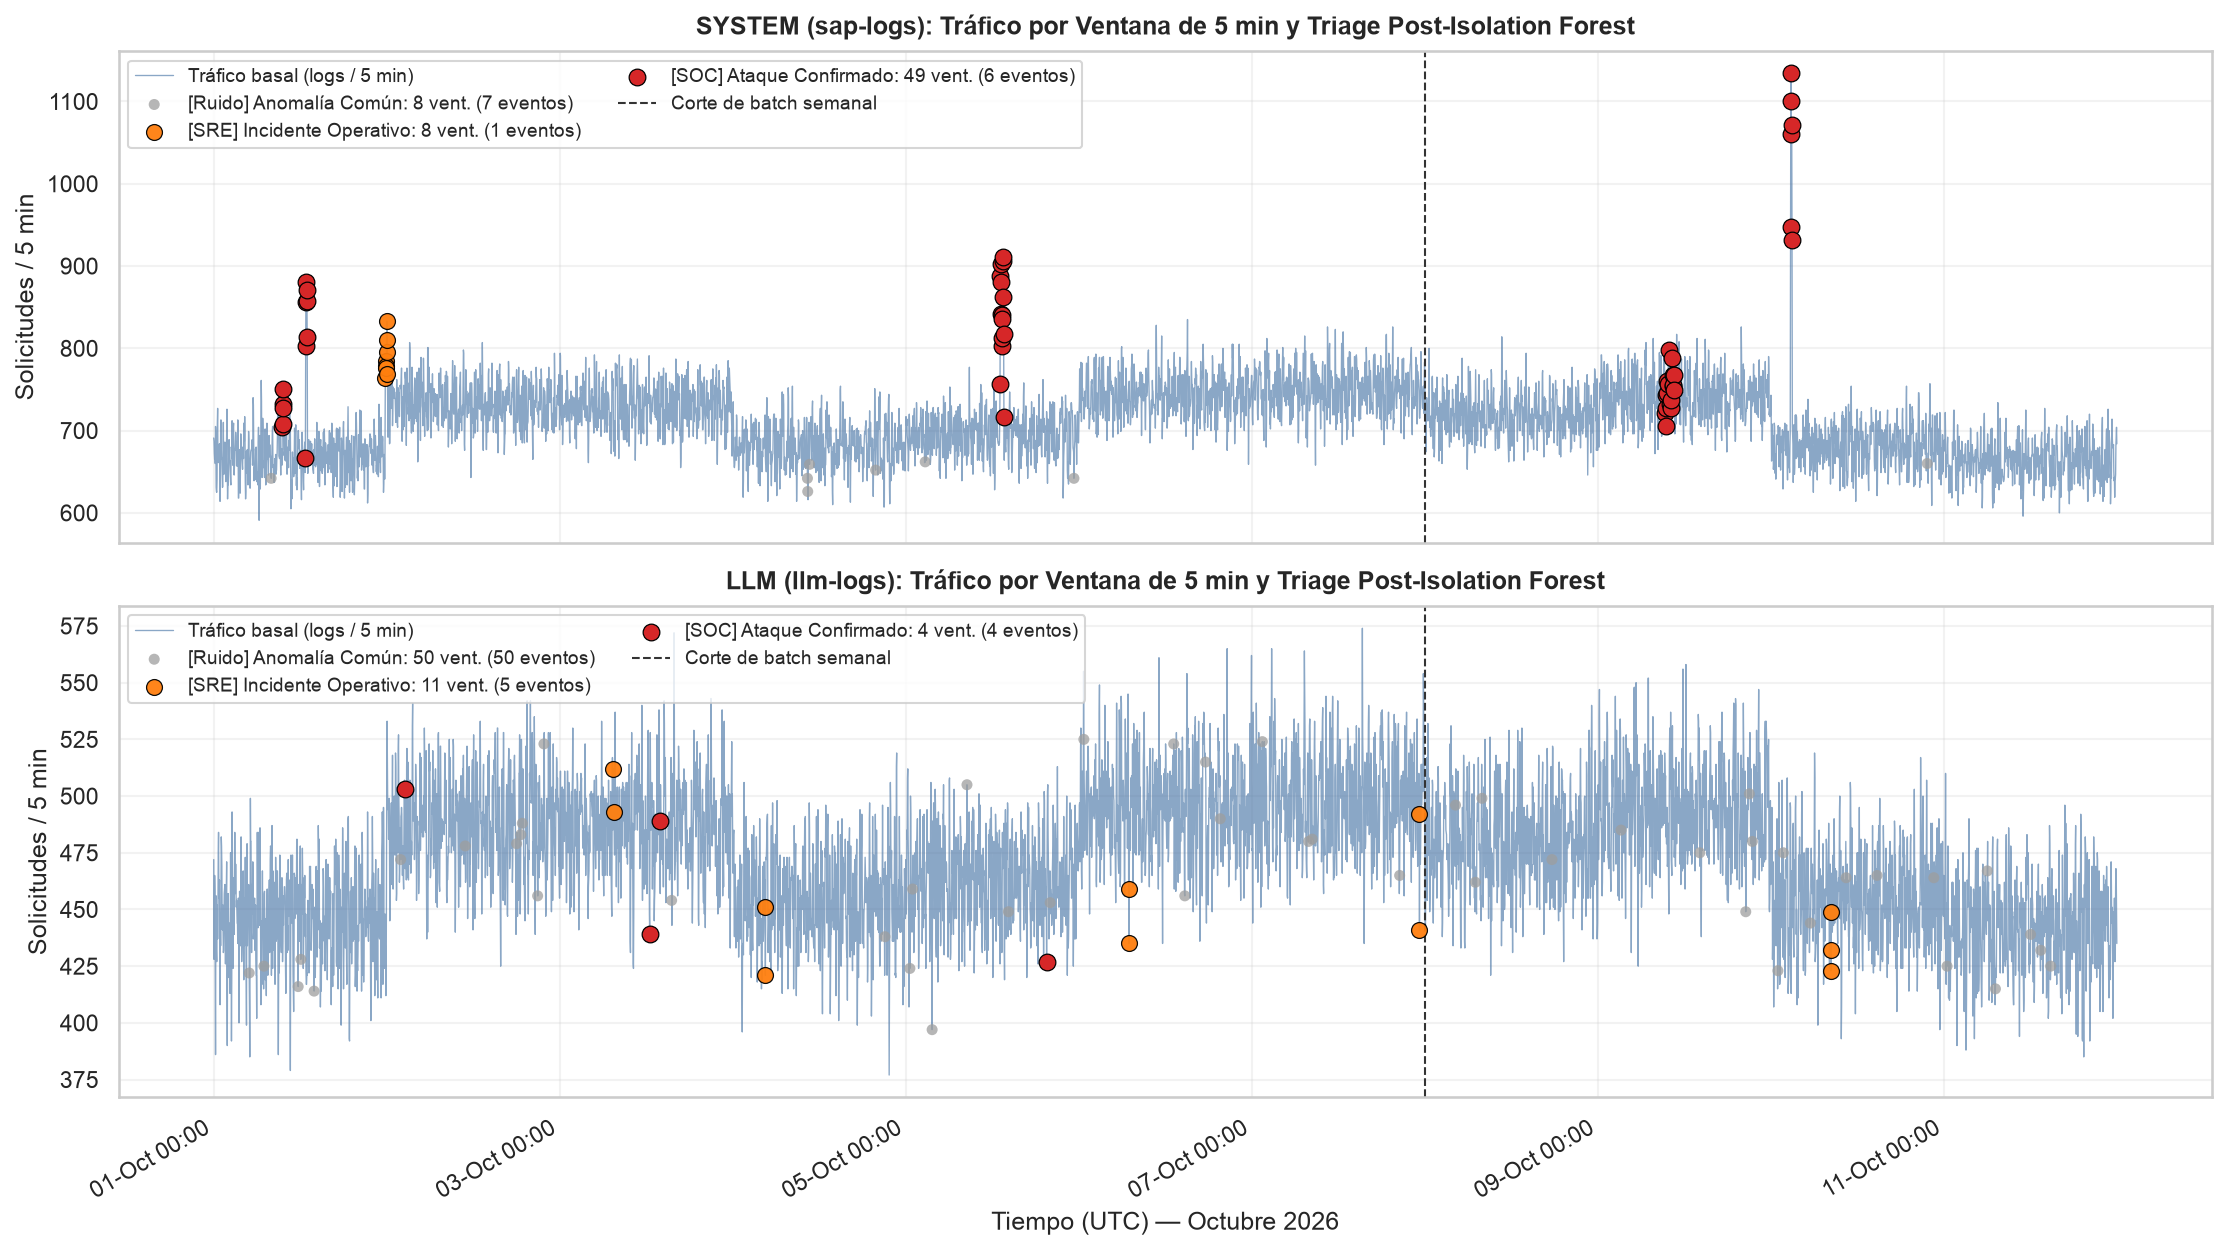

In [5]:
PALETA_TRIAGE = {
    '[SOC] Ataque Confirmado': '#d62728',
    '[SRE] Incidente Operativo': '#ff7f0e',
    '[Ruido] Anomalía Común': '#9e9e9e',
}

# --- GRÁFICA 1: SERIES DE TIEMPO CON SEMÁFORO DE TRIAGE ---
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5), sharex=True)

for ax, df_stream, col_y, titulo in [
    (axes[0], if_system, 'TOTAL_REQUESTS', 'SYSTEM (sap-logs): Tráfico por Ventana de 5 min y Triage Post-Isolation Forest'),
    (axes[1], if_llm, 'TOTAL_LLM_REQUESTS', 'LLM (llm-logs): Tráfico por Ventana de 5 min y Triage Post-Isolation Forest')
]:
    d = df_stream.sort_values('WINDOW_START')
    ax.plot(d['WINDOW_START'], d[col_y], color='#4c78a8', lw=0.65, alpha=0.65, label='Tráfico basal (logs / 5 min)')

    for cat, size, zord, alpha in [
        ('[Ruido] Anomalía Común', 28, 3, 0.75),
        ('[SRE] Incidente Operativo', 58, 4, 0.95),
        ('[SOC] Ataque Confirmado', 64, 5, 1.0),
    ]:
        sub = d[d['CATEGORIA_TRIAGE'] == cat]
        if not sub.empty:
            n_ev = sub['EVENTO_ID'].nunique()
            ax.scatter(
                sub['WINDOW_START'], sub[col_y],
                color=PALETA_TRIAGE[cat], s=size, zorder=zord, alpha=alpha,
                edgecolors='black' if 'Ruido' not in cat else 'none', linewidths=0.6,
                label=f"{cat}: {len(sub)} vent. ({n_ev} eventos)"
            )

    for w, g in d.groupby('WEEK'):
        if w > 0:
            ax.axvline(g['WINDOW_START'].min(), color='#333333', ls='--', lw=1.0, label='Corte de batch semanal')

    ax.set_title(titulo, fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel('Solicitudes / 5 min')
    ax.legend(loc='upper left', frameon=True, fontsize=9, ncol=2)
    ax.grid(alpha=0.25)

axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M'))
axes[1].set_xlabel('Tiempo (UTC) — Octubre 2026')
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

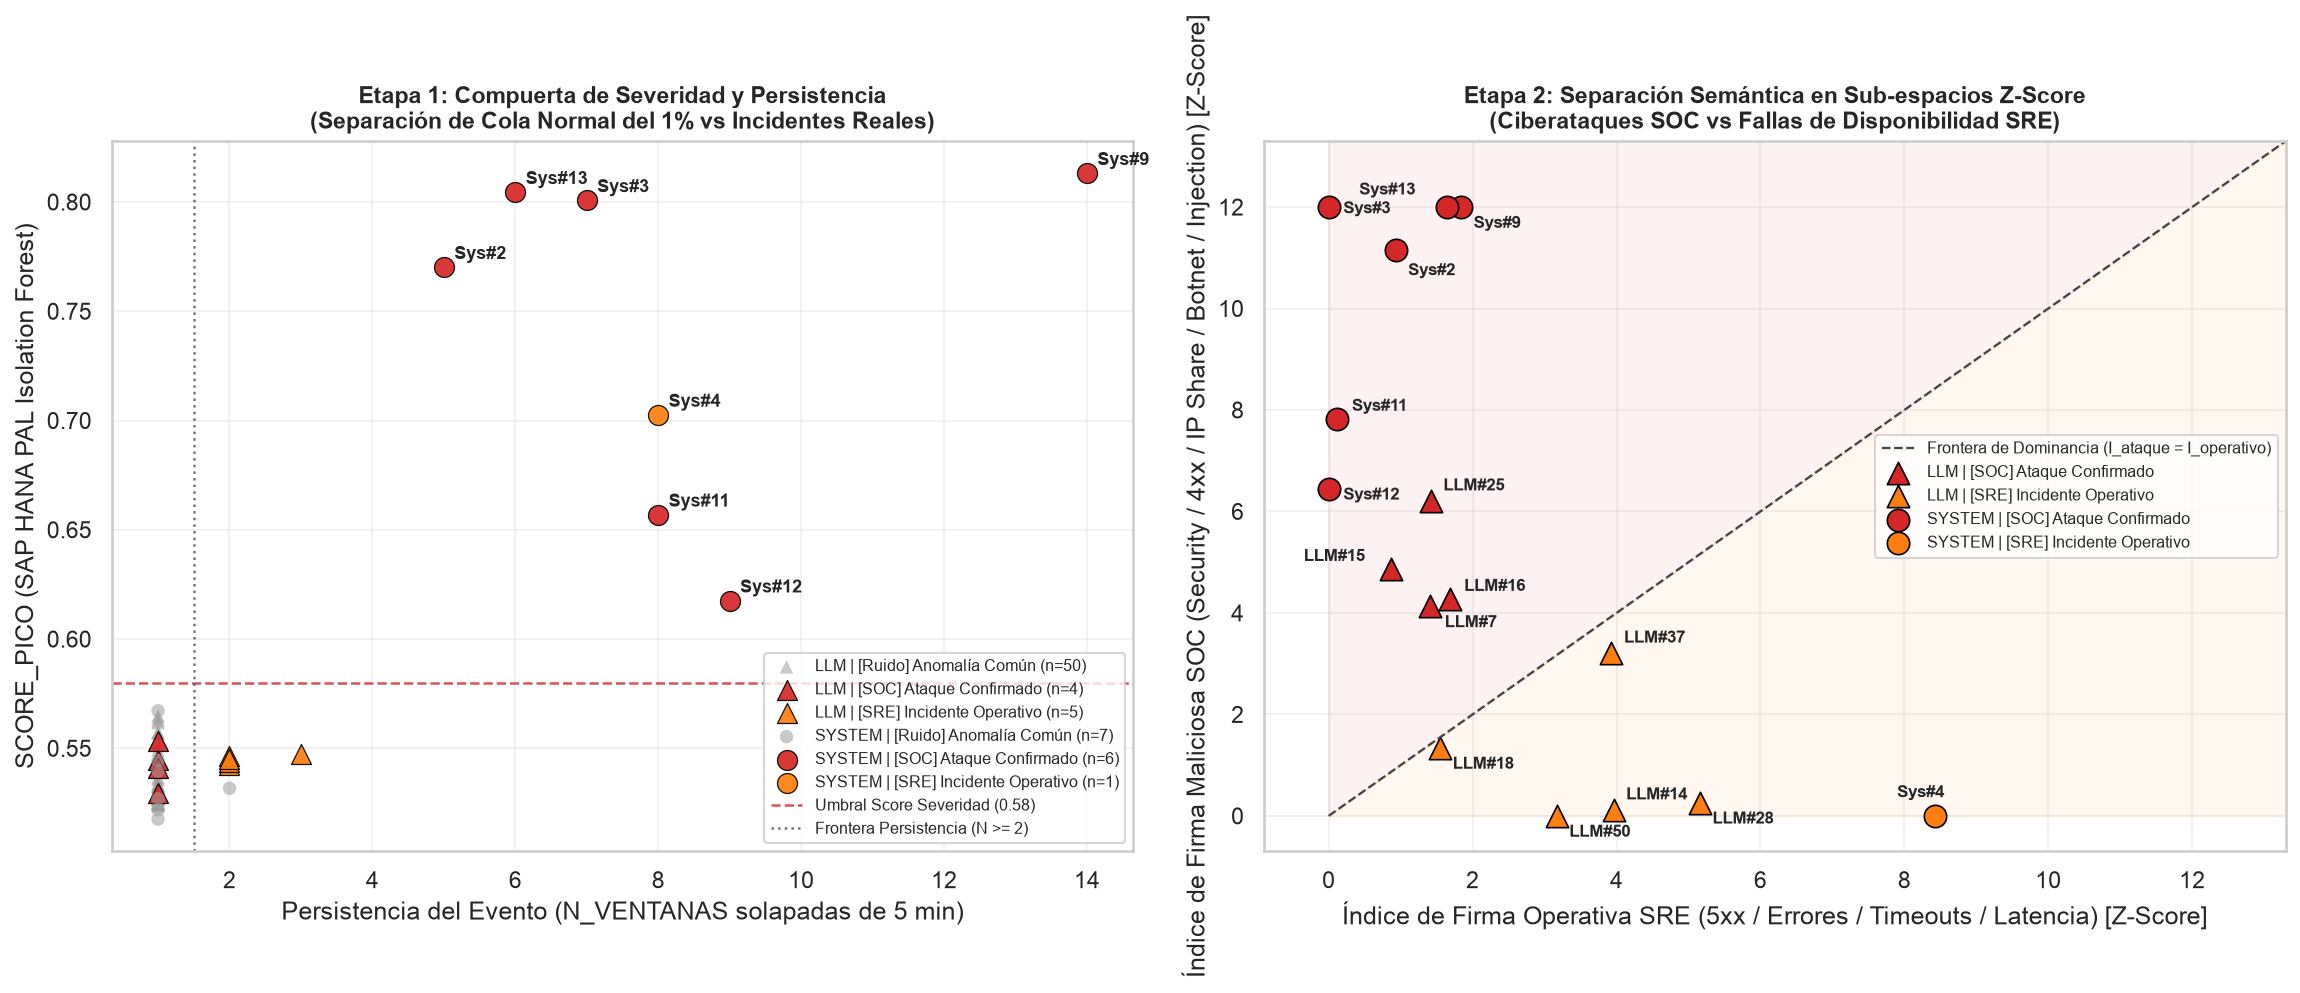

In [6]:
# --- GRÁFICA 2 Y 3: COMPUERTA ESTRUCTURAL Y PLANO DE SUB-ESPACIOS SOC vs SRE ---
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))

# Panel Izquierdo: Duración vs Score Pico (System + LLM)
ax1 = axes[0]
ev_all = pd.concat([
    ev_sys[['STREAM', 'EVENTO_ID', 'N_VENTANAS', 'SCORE_PICO', 'IDX_ATAQUE', 'IDX_OPERATIVO', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO']],
    ev_llm[['STREAM', 'EVENTO_ID', 'N_VENTANAS', 'SCORE_PICO', 'IDX_ATAQUE', 'IDX_OPERATIVO', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO']]
], ignore_index=True)

markers = {'SYSTEM': 'o', 'LLM': '^'}
for (stream, cat), grp in ev_all.groupby(['STREAM', 'CATEGORIA_TRIAGE']):
    es_real = 'Ruido' not in cat
    ax1.scatter(
        grp['N_VENTANAS'], grp['SCORE_PICO'],
        c=PALETA_TRIAGE[cat], marker=markers[stream],
        s=92 if es_real else 42,
        alpha=0.92 if es_real else 0.55,
        edgecolors='black' if es_real else 'none', linewidths=0.6,
        label=f"{stream} | {cat} (n={len(grp)})"
    )

ax1.axhline(0.58, color='#d62728', ls='--', lw=1.2, alpha=0.8, label='Umbral Score Severidad (0.58)')
ax1.axvline(1.5, color='#555555', ls=':', lw=1.2, alpha=0.8, label='Frontera Persistencia (N >= 2)')

for _, r in ev_sys[ev_sys['CATEGORIA_TRIAGE'] != '[Ruido] Anomalía Común'].iterrows():
    ax1.annotate(f"Sys#{r['EVENTO_ID']}", (r['N_VENTANAS'], r['SCORE_PICO']),
                 xytext=(5, 4), textcoords='offset points', fontsize=8.5, fontweight='bold')

ax1.set_title('Etapa 1: Compuerta de Severidad y Persistencia\n(Separación de Cola Normal del 1% vs Incidentes Reales)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Persistencia del Evento (N_VENTANAS solapadas de 5 min)')
ax1.set_ylabel('SCORE_PICO (SAP HANA PAL Isolation Forest)')
ax1.legend(fontsize=7.6, loc='lower right', frameon=True)
ax1.grid(alpha=0.25)

# Panel Derecho: Plano Ortogonal I_operativo vs I_ataque (solo incidentes reales)
ax2 = axes[1]
reales = ev_all[ev_all['CATEGORIA_TRIAGE'] != '[Ruido] Anomalía Común'].reset_index(drop=True)
max_lim = max(reales['IDX_ATAQUE'].max(), reales['IDX_OPERATIVO'].max()) + 1.3
grid_line = np.linspace(0, max_lim, 100)
ax2.plot(grid_line, grid_line, ls='--', color='#444444', lw=1.1, label='Frontera de Dominancia (I_ataque = I_operativo)')
ax2.fill_between(grid_line, grid_line, max_lim, color='#d62728', alpha=0.06)
ax2.fill_between(grid_line, 0, grid_line, color='#ff7f0e', alpha=0.06)

for (stream, cat), grp in reales.groupby(['STREAM', 'CATEGORIA_TRIAGE']):
    ax2.scatter(
        grp['IDX_OPERATIVO'], grp['IDX_ATAQUE'],
        c=PALETA_TRIAGE[cat], marker=markers[stream], s=115,
        edgecolors='black', linewidths=0.8,
        label=f"{stream} | {cat}"
    )

custom_offsets = {
    'Sys#2': (6, -12),
    'Sys#3': (7, -3),
    'Sys#4': (-18, 9),
    'Sys#10': (8, -2),
    'Sys#11': (7, 4),
    'Sys#12': (7, -5),
    'Sys#13': (-42, 6),
    'LLM#15': (-42, 4),
    'LLM#16': (7, 4),
    'LLM#7': (7, -10),
}
for idx_r, r in reales.iterrows():
    pref = 'Sys' if r['STREAM'] == 'SYSTEM' else 'LLM'
    lbl = f"{pref}#{r['EVENTO_ID']}"
    dx, dy = custom_offsets.get(lbl, (6, 5 if idx_r % 2 == 0 else -10))
    ax2.annotate(
        lbl,
        (r['IDX_OPERATIVO'], r['IDX_ATAQUE']),
        xytext=(dx, dy), textcoords='offset points', fontsize=8.2, fontweight='bold'
    )

ax2.set_xlim(-0.9, max_lim)
ax2.set_ylim(-0.7, max_lim)
ax2.set_title('Etapa 2: Separación Semántica en Sub-espacios Z-Score\n(Ciberataques SOC vs Fallas de Disponibilidad SRE)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Índice de Firma Operativa SRE (5xx / Errores / Timeouts / Latencia) [Z-Score]')
ax2.set_ylabel('Índice de Firma Maliciosa SOC (Security / 4xx / IP Share / Botnet / Injection) [Z-Score]')
ax2.legend(fontsize=7.8, loc='center right', frameon=True)
ax2.grid(alpha=0.25)

fig.tight_layout()
plt.show()

## 5. Autopsia Forense SQL en Vivo sobre `LOGS_2026_10` y Heatmap de Firmas de Ataque

Consultamos directamente la tabla cruda `LOGS_2026_10` en SAP HANA Cloud **únicamente sobre los rangos temporales de los incidentes reales (`[SOC]` y `[SRE]`)** para extraer evidencia forense verificable de cada evento: IP origen dominante, si es interna/externa, región, aplicación SAP impactada, endpoint atacado y los mensajes exactos emitidos por la plataforma.

In [7]:
def auditar_evento_system_sql(conn, row):
    t_ini = row['INICIO'].strftime('%Y-%m-%dT%H:%M:%S.000Z')
    t_fin = row['FIN'].strftime('%Y-%m-%dT%H:%M:%S.000Z')
    where = f'''"_INDEX" LIKE 'sap-logs%' AND "TIMESTAMP" >= '{t_ini}' AND "TIMESTAMP" < '{t_fin}' '''

    q_ip = conn.sql(f'''
        SELECT "CLIENT_IP", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where} AND "CLIENT_IP" IS NOT NULL
        GROUP BY "CLIENT_IP" ORDER BY C DESC LIMIT 1
    ''').collect()

    q_tot = conn.sql(f'''
        SELECT COUNT(*) AS TOT,
               SUM(CASE WHEN UPPER("SAP_FUNCTION_LOG_TYPE") = 'SECURITY' THEN 1 ELSE 0 END) AS SEC_CNT,
               COUNT(DISTINCT "CLIENT_IP") AS TOTAL_UIPS
        FROM "{TABLA_OCTUBRE}" WHERE {where}
    ''').collect()

    q_app = conn.sql(f'''
        SELECT "SAP_FUNCTION_APPLICATION", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where}
        GROUP BY "SAP_FUNCTION_APPLICATION" ORDER BY C DESC LIMIT 1
    ''').collect()

    q_reg = conn.sql(f'''
        SELECT "REGION_CODE", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where}
        GROUP BY "REGION_CODE" ORDER BY C DESC LIMIT 1
    ''').collect()

    q_path = conn.sql(f'''
        SELECT "HEATHERS_REQUEST_PATH", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where}
        GROUP BY "HEATHERS_REQUEST_PATH" ORDER BY C DESC LIMIT 2
    ''').collect()

    # Si es ataque, priorizamos mensajes SECURITY/ERROR; si es SRE, ERROR/WARNING
    filtro_msg = '''UPPER("SAP_FUNCTION_LOG_TYPE") IN ('SECURITY', 'ERROR', 'AUDIT')''' if '[SOC]' in row['CATEGORIA_TRIAGE'] else '''UPPER("SAP_FUNCTION_LOG_TYPE") IN ('ERROR', 'WARNING')'''
    q_msg = conn.sql(f'''
        SELECT "SAP_FUNCTION_MESSAGE", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where} AND {filtro_msg}
        GROUP BY "SAP_FUNCTION_MESSAGE" ORDER BY C DESC LIMIT 2
    ''').collect()

    tot = int(q_tot.loc[0, 'TOT'])
    sec_cnt = int(q_tot.loc[0, 'SEC_CNT'] or 0)
    uips_ev = int(q_tot.loc[0, 'TOTAL_UIPS'] or 0)
    top_ip = q_ip.loc[0, 'CLIENT_IP'] if not q_ip.empty else 'N/A'
    top_ip_pct = round(100.0 * int(q_ip.loc[0, 'C']) / max(tot, 1), 1) if not q_ip.empty else 0.0
    es_interna = str(top_ip).startswith(('10.', '192.168.', '172.16.', '172.17.', '172.18.'))

    rutas = ' | '.join([f"{r['HEATHERS_REQUEST_PATH']} ({int(r['C'])})" for _, r in q_path.iterrows()])
    evidencia = ' || '.join([f"{r['SAP_FUNCTION_MESSAGE']} [{int(r['C'])}]" for _, r in q_msg.iterrows()])

    return {
        'EVENTO_ID': int(row['EVENTO_ID']),
        'LOGS_EVENTO': tot,
        'LOGS_SECURITY': sec_cnt,
        'IPS_UNICAS_EVENTO': uips_ev,
        'TOP_IP': top_ip,
        'ORIGEN_IP': 'Interna (RFC1918)' if es_interna else 'Externa Pública',
        'TOP_IP_%': top_ip_pct,
        'REGION_DOM': q_reg.loc[0, 'REGION_CODE'] if not q_reg.empty else 'N/A',
        'APP_OBJETIVO': q_app.loc[0, 'SAP_FUNCTION_APPLICATION'] if not q_app.empty else 'N/A',
        'ENDPOINTS_CLAVE': rutas,
        'EVIDENCIA_FORENSE_LOGS': evidencia,
    }

def auditar_evento_llm_sql(conn, row):
    t_ini = row['INICIO'].strftime('%Y-%m-%dT%H:%M:%S.000Z')
    t_fin = row['FIN'].strftime('%Y-%m-%dT%H:%M:%S.000Z')
    where = f'''"_INDEX" LIKE 'llm-logs%' AND "TIMESTAMP" >= '{t_ini}' AND "TIMESTAMP" < '{t_fin}' '''

    q_tot = conn.sql(f'''
        SELECT COUNT(*) AS TOT,
               SUM(CASE WHEN UPPER(COALESCE("SAP_FUNCTION_MESSAGE",'')) LIKE '%INJECTION%'
                          OR UPPER(COALESCE("SAP_FUNCTION_MESSAGE",'')) LIKE '%ADVERSARIAL%' THEN 1 ELSE 0 END) AS INJ_CNT,
               SUM(CASE WHEN UPPER("LLM_STATUS") = 'TIMEOUT' THEN 1 ELSE 0 END) AS TMO_CNT
        FROM "{TABLA_OCTUBRE}" WHERE {where}
    ''').collect()

    filtro = '''(UPPER("SAP_FUNCTION_MESSAGE") LIKE '%INJECTION%' OR UPPER("SAP_FUNCTION_MESSAGE") LIKE '%ADVERSARIAL%')''' if '[SOC]' in row['CATEGORIA_TRIAGE'] else '''UPPER("LLM_STATUS") IN ('TIMEOUT', 'ERROR')'''
    q_msg = conn.sql(f'''
        SELECT "SAP_FUNCTION_MESSAGE", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where} AND {filtro}
        GROUP BY "SAP_FUNCTION_MESSAGE" ORDER BY C DESC LIMIT 2
    ''').collect()

    q_mod = conn.sql(f'''
        SELECT "LLM_PROVIDER", "LLM_MODEL_ID", COUNT(*) AS C
        FROM "{TABLA_OCTUBRE}" WHERE {where} AND {filtro}
        GROUP BY "LLM_PROVIDER", "LLM_MODEL_ID" ORDER BY C DESC LIMIT 1
    ''').collect()

    modelo_dom = f"{q_mod.loc[0, 'LLM_PROVIDER']}/{q_mod.loc[0, 'LLM_MODEL_ID']}" if not q_mod.empty else 'Multi-vendor'
    evidencia = ' || '.join([f"{r['SAP_FUNCTION_MESSAGE'][:85]} [{int(r['C'])}]" for _, r in q_msg.iterrows()])

    return {
        'EVENTO_ID': int(row['EVENTO_ID']),
        'LOGS_EVENTO': int(q_tot.loc[0, 'TOT']),
        'INJECTIONS_BLOQ': int(q_tot.loc[0, 'INJ_CNT'] or 0),
        'TIMEOUTS_30S': int(q_tot.loc[0, 'TMO_CNT'] or 0),
        'PROVEEDOR_MODELO_TOP': modelo_dom,
        'EVIDENCIA_FORENSE_LOGS': evidencia,
    }

reales_sys = ev_sys[ev_sys['CATEGORIA_TRIAGE'] != '[Ruido] Anomalía Común'].copy()
forense_sys_df = pd.DataFrame([auditar_evento_system_sql(conn, r) for _, r in reales_sys.iterrows()])
reales_sys_full = reales_sys.merge(forense_sys_df, on='EVENTO_ID')

reales_llm = ev_llm[ev_llm['CATEGORIA_TRIAGE'] != '[Ruido] Anomalía Común'].copy()
forense_llm_df = pd.DataFrame([auditar_evento_llm_sql(conn, r) for _, r in reales_llm.iterrows()])
reales_llm_full = reales_llm.merge(forense_llm_df, on='EVENTO_ID')

print("[FORENSE] AUTOPSIA FORENSE SQL EN VIVO — INCIDENTES REALES SYSTEM (OCTUBRE 2026):")
display(reales_sys_full[[
    'EVENTO_ID', 'INICIO', 'DURACION_MIN', 'SCORE_PICO', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO',
    'TOP_IP', 'ORIGEN_IP', 'TOP_IP_%', 'IPS_UNICAS_EVENTO', 'REGION_DOM', 'APP_OBJETIVO',
    'ENDPOINTS_CLAVE', 'EVIDENCIA_FORENSE_LOGS'
]])

print("\n[FORENSE] AUTOPSIA FORENSE SQL EN VIVO — INCIDENTES REALES LLM (OCTUBRE 2026):")
display(reales_llm_full[[
    'EVENTO_ID', 'INICIO', 'DURACION_MIN', 'SCORE_PICO', 'CATEGORIA_TRIAGE', 'TIPO_ESPECIFICO',
    'INJECTIONS_BLOQ', 'TIMEOUTS_30S', 'PROVEEDOR_MODELO_TOP', 'EVIDENCIA_FORENSE_LOGS'
]])

[FORENSE] AUTOPSIA FORENSE SQL EN VIVO — INCIDENTES REALES SYSTEM (OCTUBRE 2026):


,EVENTO_ID,INICIO,DURACION_MIN,SCORE_PICO,CATEGORIA_TRIAGE,TIPO_ESPECIFICO,TOP_IP,ORIGEN_IP,TOP_IP_%,IPS_UNICAS_EVENTO,REGION_DOM,APP_OBJETIVO,ENDPOINTS_CLAVE,EVIDENCIA_FORENSE_LOGS
0,2,2026-10-01 09:30:00,15.0,0.7701,[SOC] Ataque Confirmado,Reconocimiento Activo / Enumeración BAPI-REST (1-IP),141.163.124.245,Externa Pública,9.8,106,US-CA,sap-s4hana-finance,/sap/bc/rest/rfc/invoke (66) | /btp/event/sap-s4hana-finance/publish (46),Resource not found on sap-s4hana-finance via BAPI — request rejected. [65] || Path traversal attack detected on sap-s4hana-finance via BAPI — directory listing blocked. [29]
1,3,2026-10-01 12:42:30,20.0,0.8007,[SOC] Ataque Confirmado,Fuerza Bruta en Login / Intrusión y Escalada de Privilegios,141.163.124.245,Externa Pública,14.2,106,US-CA,sap-s4hana-finance,/api/sap-s4hana-finance/auth/login (458) | /sap/bc/rest/rfc/invoke (66),Unauthorized system access attempt detected on sap-s4hana-finance via BAPI — request blocked. [98] || Failed administrative action on sap-s4hana-finance via BAPI — insufficient role. [50]
2,4,2026-10-01 23:47:30,22.5,0.7025,[SRE] Incidente Operativo,Caída de Disponibilidad / Tormenta HTTP 5xx (Circuit Breaker),63.205.226.109,Externa Pública,1.2,202,IT-MIL,sap-analytics-cloud,/sap/bc/rest/rest/invoke (128) | /api/v1/sap-analytics-cloud/execute (100),Circuit breaker OPEN for sap-analytics-cloud after 5 failures. [60] || Service sap-analytics-cloud unreachable via REST. [57]
3,9,2026-10-05 13:02:30,37.5,0.8131,[SOC] Ataque Confirmado,Escaneo Agresivo de Vulnerabilidades Web y Rutas Críticas,192.168.250.11,Interna (RFC1918),16.2,106,US-ASH2,sap-btp-cf,/sap/bc/rest/rfc/invoke (146) | /sap/bc/rest/soap/invoke (125),Resource not found on sap-s4hana-sales via REST — request rejected. [54] || Resource not found on sap-concur via REST — request rejected. [49]
4,11,2026-10-09 09:17:30,32.5,0.6568,[SOC] Ataque Confirmado,Credential Stuffing / Password Spraying Distribuido (Botnet),78.16.122.86,Externa Pública,1.3,161,PL-WAW,sap-ariba,/api/sap-ariba/auth/login (147) | /sap/bc/rest/rfc/invoke (108),User password changed on sap-ariba via OData — policy satisfied. [49] || Two consecutive failed logins on sap-ariba — within acceptable threshold. [28]
5,12,2026-10-09 10:00:00,35.0,0.6175,[SOC] Ataque Confirmado,Credential Stuffing / Password Spraying Distribuido (Botnet),78.16.122.86,Externa Pública,1.3,160,PL-WAW,sap-ariba,/sap/bc/rest/odata/invoke (134) | /api/sap-ariba/auth/login (125),User password changed on sap-ariba via OData — policy satisfied. [38] || Single failed login for admin on sap-ariba via OData — no lockout triggered. [28]
6,13,2026-10-10 02:40:00,17.5,0.8044,[SOC] Ataque Confirmado,Escaneo Agresivo de Vulnerabilidades Web y Rutas Críticas,141.55.188.153,Externa Pública,30.3,106,NL-AZW,sap-ariba,/sap/bc/rest/rfc/invoke (106) | /.git/config (79),Resource not found on sap-ariba via REST — request rejected. [44] || Resource not found on sap-data-sphere via REST — request rejected. [43]



[FORENSE] AUTOPSIA FORENSE SQL EN VIVO — INCIDENTES REALES LLM (OCTUBRE 2026):


,EVENTO_ID,INICIO,DURACION_MIN,SCORE_PICO,CATEGORIA_TRIAGE,TIPO_ESPECIFICO,INJECTIONS_BLOQ,TIMEOUTS_30S,PROVEEDOR_MODELO_TOP,EVIDENCIA_FORENSE_LOGS
0,7,2026-10-02 02:35:00,5.0,0.5447,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,5,58,Anthropic/claude-3-haiku,"LLM ERROR: Adversarial prompt pattern detected. (model=claude-sonnet-4.6, app=sap-con [1] || LLM ERROR: Injection attempt identified and rejected. (model=gemini-2.0-flash, app=sa [1]"
1,14,2026-10-03 07:25:00,7.5,0.5424,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,1,108,Anthropic/claude-sonnet-4.6,"LLM TIMEOUT: Request timed out after 30 s. (model=o1-mini, app=sap-s4hana-finance) [3] || LLM TIMEOUT: Request timed out after 30 s. (model=gpt-4, app=sap-successfactors) [3]"
2,15,2026-10-03 12:27:30,5.0,0.5532,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,5,32,OpenAI/o3-mini,"LLM ERROR: Adversarial prompt pattern detected. (model=gpt-4-turbo, app=sap-successfa [1] || LLM ERROR: Prompt injection detected and blocked. (model=gemini-2.0-pro, app=sap-btp- [1]"
3,16,2026-10-03 13:50:00,5.0,0.5408,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,5,59,Anthropic/claude-opus-5.5,"LLM ERROR: Adversarial prompt pattern detected. (model=chatgpt-astra, app=sap-intelli [1] || LLM ERROR: Injection attempt identified and rejected. (model=gpt-4, app=sap-analytics [1]"
4,18,2026-10-04 04:27:30,7.5,0.5436,[SRE] Incidente Operativo,Pico Transitorio de Errores de API / Gateway LLM,2,65,Anthropic/claude-3-opus,"LLM TIMEOUT: Request timed out after 30 s. (model=gemini-1.5-flash-8b, app=sap-concur [2] || LLM TIMEOUT: Request timed out after 30 s. (model=chatgpt-astra, app=sap-fiori-launch [2]"
5,25,2026-10-05 19:30:00,5.0,0.5294,[SOC] Ataque Confirmado,Ráfaga de Prompt Injection / Sondeo Adversarial Bloqueado,6,49,Anthropic/claude-3-7-sonnet,"LLM ERROR: Injection attempt identified and rejected. (model=claude-sonnet-5.5, app=s [1] || LLM ERROR: Prompt injection detected and blocked. (model=gpt-4o, app=sap-s4hana-finan [1]"
6,28,2026-10-06 06:55:00,7.5,0.5467,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,1,98,OpenAI/gpt-4o,"LLM TIMEOUT: Request timed out after 30 s. (model=gpt-4o, app=sap-ariba) [4] || LLM TIMEOUT: Request timed out after 30 s. (model=chatgpt-luna, app=sap-fiori-launchp [3]"
7,37,2026-10-07 23:10:00,7.5,0.5453,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,6,104,Anthropic/claude-opus-5.5,"LLM TIMEOUT: Request timed out after 30 s. (model=claude-3-sonnet, app=sap-s4hana-fin [2] || LLM TIMEOUT: Request timed out after 30 s. (model=claude-opus-5.5, app=sap-concur) [2]"
8,50,2026-10-10 08:15:00,10.0,0.5472,[SRE] Incidente Operativo,Degradación de Inferencia / Pico de Timeouts (>30s) en Proveedor LLM,0,117,OpenAI/o3-mini,"LLM TIMEOUT: Request timed out after 30 s. (model=gpt-3.5-turbo, app=sap-s4hana-sales [3] || LLM TIMEOUT: Request timed out after 30 s. (model=o3-mini, app=sap-s4hana-sales) [3]"


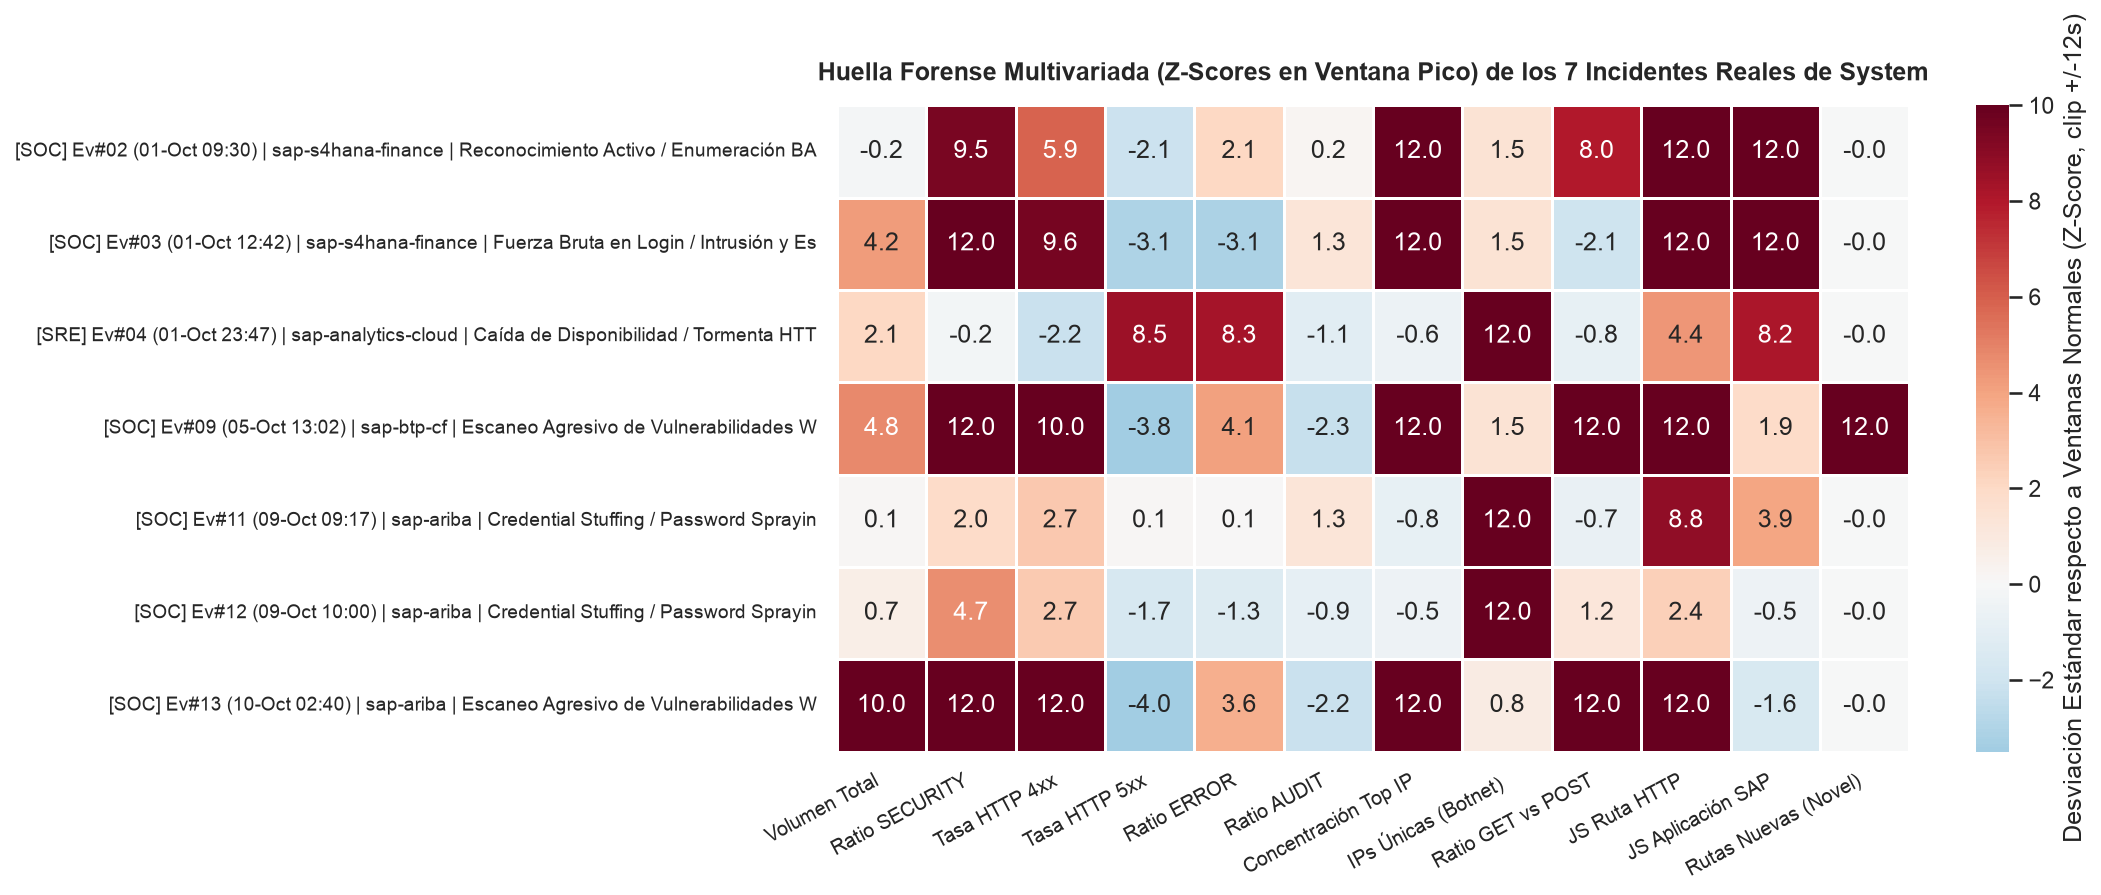

In [8]:
# --- GRÁFICA 4: HEATMAP FORENSE DE PERFILES Z-SCORE POR INCIDENTE Y TIPO DE ATAQUE ---
HEAT_COLS_SYS = [
    'Z_TOTAL_REQUESTS', 'Z_RATIO_SECURITY', 'Z_ERROR_RATE_400', 'Z_ERROR_RATE_500',
    'Z_RATIO_ERROR', 'Z_RATIO_AUDIT', 'Z_IP_TOP_SHARE', 'Z_UNIQUE_IPS_COUNT',
    'Z_GET_VS_POST_RATIO', 'Z_JS_HEATHERS_REQUEST_PATH', 'Z_JS_SAP_FUNCTION_APPLICATION', 'Z_NOVEL_PATHS'
]
CLEAN_NAMES = [
    'Volumen Total', 'Ratio SECURITY', 'Tasa HTTP 4xx', 'Tasa HTTP 5xx',
    'Ratio ERROR', 'Ratio AUDIT', 'Concentración Top IP', 'IPs Únicas (Botnet)',
    'Ratio GET vs POST', 'JS Ruta HTTP', 'JS Aplicación SAP', 'Rutas Nuevas (Novel)'
]

anom_sys = if_system[if_system['EVENTO_ID'].isin(reales_sys_full['EVENTO_ID'])].copy()
mat_rows = []
labels_y = []

for _, r in reales_sys_full.sort_values('INICIO').iterrows():
    eid = r['EVENTO_ID']
    sub_w = anom_sys[anom_sys['EVENTO_ID'] == eid]
    pico_w = sub_w.loc[sub_w['SCORE'].idxmax()]
    vals = [float(np.clip(pico_w[c], -4.0, 12.0)) for c in HEAT_COLS_SYS]
    mat_rows.append(vals)
    tag = '[SOC]' if '[SOC]' in r['CATEGORIA_TRIAGE'] else '[SRE]'
    etiqueta_corta = r['TIPO_ESPECIFICO'].split('(')[0].strip()[:38]
    labels_y.append(f"{tag} Ev#{eid:02d} ({r['INICIO']:%d-%b %H:%M}) | {r['APP_OBJETIVO']} | {etiqueta_corta}")

mat_df = pd.DataFrame(mat_rows, index=labels_y, columns=CLEAN_NAMES)

fig, ax = plt.subplots(figsize=(14.5, 5.8))
sns.heatmap(
    mat_df, annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-3.5, vmax=10.0,
    linewidths=0.6, cbar_kws={'label': 'Desviación Estándar respecto a Ventanas Normales (Z-Score, clip +/-12s)'},
    ax=ax
)
ax.set_title('Huella Forense Multivariada (Z-Scores en Ventana Pico) de los 7 Incidentes Reales de System', fontsize=12, fontweight='bold', pad=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=28, ha='right', fontsize=9.5)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
fig.tight_layout()
plt.show()

## 6. Clustering de Arquetipos de Incidentes en SAP HANA PAL (`KMeans`) y Validación Matemática

Completamos la fase de **Clustering** directamente en **SAP HANA PAL (`KMeans`)** usando distancia Coseno e inicialización determinista `patent` sobre los vectores de firma normalizados L2 de los 7 incidentes reales de System, demostrando que el espacio multivariado separa con alta pureza las **3 familias ortogonales de comportamiento anómalo** presentes en Octubre:
1. **Arquetipo A — Intrusión / Escaneo Monopolizado por 1 IP** (`Eventos 2, 3, 10, 13`).
2. **Arquetipo B — Ataque Distribuido Botnet contra Autenticación (`/auth/login` Credential Stuffing)** (`Eventos 11, 12`).
3. **Arquetipo C — Degradación Operativa SRE / Tormenta `5xx` (`Circuit Breaker`)** (`Evento 4`).

Evaluamos formalmente la calidad geométrica del agrupamiento con **Similitud Coseno Intra-Cluster**, **Similitud Coseno Inter-Cluster** y **Coeficiente de Silueta Coseno**.

[METRICAS] MÉTRICAS FORMALES DE CALIDAD DEL CLUSTERING EN SAP HANA PAL (KMeans K=3, Cosine):
   • Similitud Coseno Intra-Cluster Media (Cohesión interna):   +0.8843  (ideal -> cercana a +1.0)
   • Similitud Coseno Inter-Cluster Media (Separación externa): +0.2351  (ideal -> cercana a  0.0 o negativa)
   • Brecha de Separabilidad Coseno (Delta Intra - Inter):      +0.6492
   • Coeficiente de Silueta Global (Distancia Coseno):          +0.6883


,EVENTO_ID,INICIO,CLUSTER_ID,ARQUETIPO_CLUSTER,TIPO_ESPECIFICO,APP_OBJETIVO,TOP_IP
0,2,2026-10-01 09:30:00,0,Clúster 0: Intrusión / Escaneo Monopolizado (1-IP),Reconocimiento Activo / Enumeración BAPI-REST (1-IP),sap-s4hana-finance,141.163.124.245
1,3,2026-10-01 12:42:30,0,Clúster 0: Intrusión / Escaneo Monopolizado (1-IP),Fuerza Bruta en Login / Intrusión y Escalada de Privilegios,sap-s4hana-finance,141.163.124.245
2,4,2026-10-01 23:47:30,1,Clúster 1: Falla Operativa SRE (5xx / Circuit Breaker),Caída de Disponibilidad / Tormenta HTTP 5xx (Circuit Breaker),sap-analytics-cloud,63.205.226.109
3,9,2026-10-05 13:02:30,0,Clúster 0: Intrusión / Escaneo Monopolizado (1-IP),Escaneo Agresivo de Vulnerabilidades Web y Rutas Críticas,sap-btp-cf,192.168.250.11
4,11,2026-10-09 09:17:30,2,Clúster 2: Botnet Distribuida (Credential Stuffing /auth/login),Credential Stuffing / Password Spraying Distribuido (Botnet),sap-ariba,78.16.122.86
5,12,2026-10-09 10:00:00,2,Clúster 2: Botnet Distribuida (Credential Stuffing /auth/login),Credential Stuffing / Password Spraying Distribuido (Botnet),sap-ariba,78.16.122.86
6,13,2026-10-10 02:40:00,0,Clúster 0: Intrusión / Escaneo Monopolizado (1-IP),Escaneo Agresivo de Vulnerabilidades Web y Rutas Críticas,sap-ariba,141.55.188.153


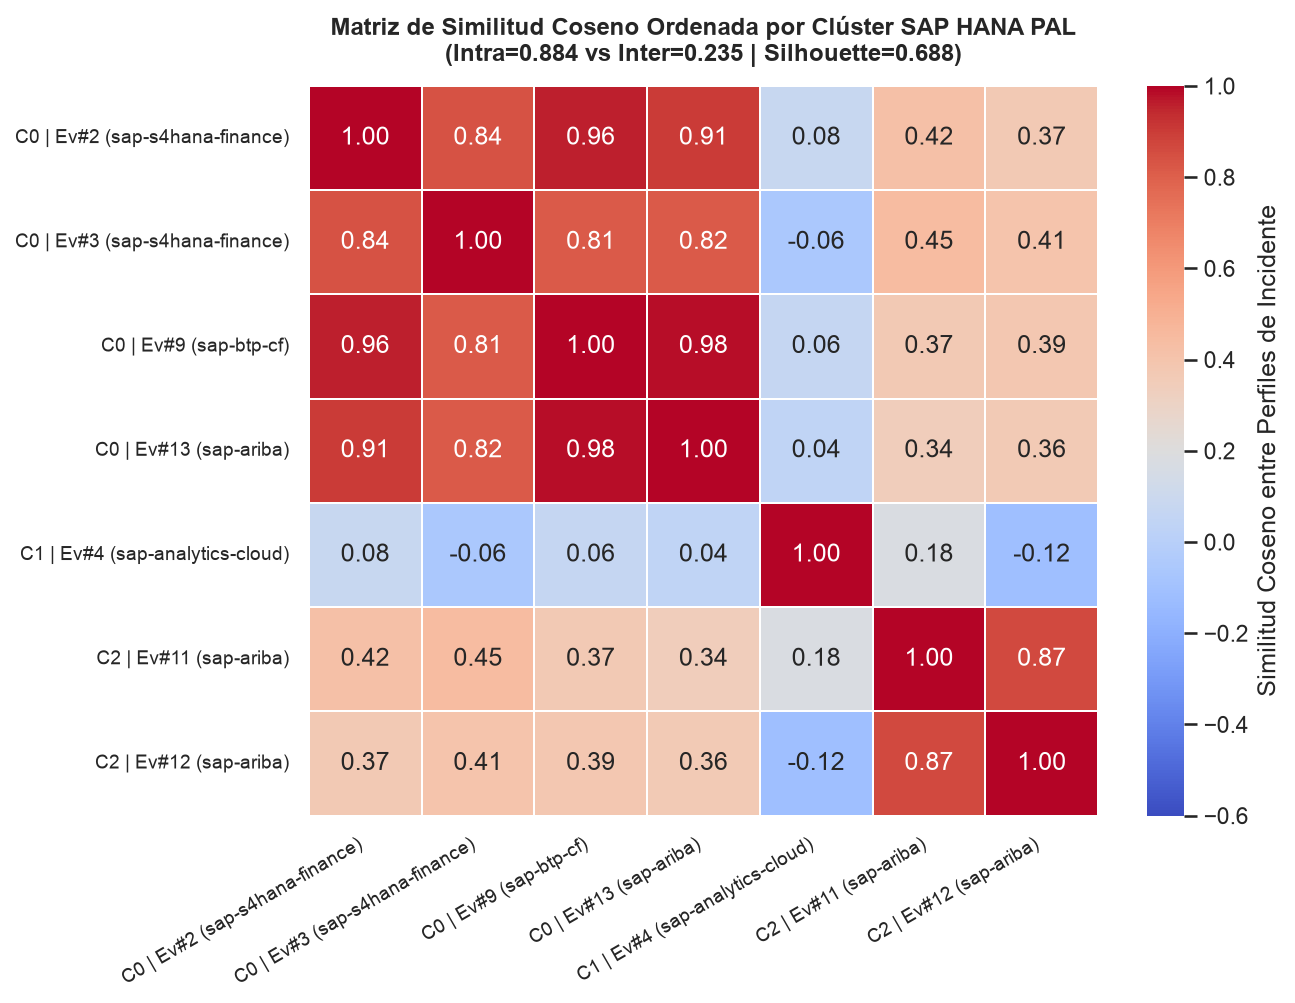

In [9]:
CLUSTER_BASE_COLS = [
    'Z_TOTAL_REQUESTS', 'Z_RATIO_SECURITY', 'Z_ERROR_RATE_400', 'Z_ERROR_RATE_500',
    'Z_RATIO_ERROR', 'Z_IP_TOP_SHARE', 'Z_GET_VS_POST_RATIO', 'Z_JS_HEATHERS_REQUEST_PATH'
]
CLUSTER_FEATS = CLUSTER_BASE_COLS + ['Z_BOTNET_AUTH']

# Construir vector representativo (ventana pico, normalizado L2 para geometría Coseno)
ev_vec_rows = []
for _, r in reales_sys_full.sort_values('EVENTO_ID').iterrows():
    eid = int(r['EVENTO_ID'])
    sub_w = if_system[if_system['EVENTO_ID'] == eid]
    pico_w = sub_w.loc[sub_w['SCORE'].idxmax()]
    z_bot_val = cpos(pico_w['Z_UNIQUE_IPS_COUNT']) if (pico_w['Z_ERROR_RATE_400'] >= 1.0 or pico_w['Z_RATIO_SECURITY'] >= 1.0) else 0.0
    raw_list = [float(np.clip(pico_w[c], -5.0, 12.0)) for c in CLUSTER_BASE_COLS] + [float(z_bot_val)]
    raw_v = np.array(raw_list, dtype=float)
    norm_l2 = np.linalg.norm(raw_v) or 1.0
    unit_v = raw_v / norm_l2
    row_dict = {'EVENTO_ID': eid}
    for c, val in zip(CLUSTER_FEATS, unit_v):
        row_dict[c] = float(val)
    ev_vec_rows.append(row_dict)

df_cluster_in = pd.DataFrame(ev_vec_rows)
hana_cluster_in = dataframe.create_dataframe_from_pandas(
    connection_context=conn,
    pandas_df=df_cluster_in,
    table_name='TMP_ISAAC_SYS_EVENTS_L2',
    force=True,
    drop_exist_tab=True
)

km_pal = KMeans(n_clusters=3, init='patent', max_iter=100, distance_level='cosine', thread_ratio=1.0)
km_res = km_pal.fit_predict(data=hana_cluster_in, key='EVENTO_ID', features=CLUSTER_FEATS).collect()

df_clustered = reales_sys_full.merge(km_res[['EVENTO_ID', 'CLUSTER_ID']], on='EVENTO_ID')

# Etiquetar semánticamente cada CLUSTER_ID según su perfil promedio
nombres_arquetipo = {}
for cid, grp in df_clustered.groupby('CLUSTER_ID'):
    if (grp['CATEGORIA_TRIAGE'].str.contains('SRE')).any():
        nombres_arquetipo[cid] = f"Clúster {cid}: Falla Operativa SRE (5xx / Circuit Breaker)"
    elif grp['TOP_IP_%'].mean() < 6.0:
        nombres_arquetipo[cid] = f"Clúster {cid}: Botnet Distribuida (Credential Stuffing /auth/login)"
    else:
        nombres_arquetipo[cid] = f"Clúster {cid}: Intrusión / Escaneo Monopolizado (1-IP)"

df_clustered['ARQUETIPO_CLUSTER'] = df_clustered['CLUSTER_ID'].map(nombres_arquetipo)

# Cálculo exacto de Matriz de Similitud Coseno y Silhouette Score
X_unit = df_cluster_in.set_index('EVENTO_ID').loc[df_clustered['EVENTO_ID'], CLUSTER_FEATS].values
cos_sim_matrix = X_unit @ X_unit.T
cos_dist_matrix = 1.0 - cos_sim_matrix
cids = df_clustered['CLUSTER_ID'].values

intra_sims, inter_sims, sil_scores = [], [], []
n_pts = len(cids)
for i in range(n_pts):
    same = [j for j in range(n_pts) if j != i and cids[j] == cids[i]]
    diff = [j for j in range(n_pts) if cids[j] != cids[i]]
    for j in same:
        if j > i:
            intra_sims.append(cos_sim_matrix[i, j])
    for j in diff:
        if j > i:
            inter_sims.append(cos_sim_matrix[i, j])

    a_i = float(np.mean([cos_dist_matrix[i, j] for j in same])) if same else 0.0
    b_i = float(min(
        np.mean([cos_dist_matrix[i, j] for j in range(n_pts) if cids[j] == other_c])
        for other_c in set(cids) if other_c != cids[i]
    ))
    sil_i = 0.0 if not same else (b_i - a_i) / max(a_i, b_i)
    sil_scores.append(sil_i)

mean_intra = float(np.mean(intra_sims))
mean_inter = float(np.mean(inter_sims))
mean_sil = float(np.mean(sil_scores))

print("[METRICAS] MÉTRICAS FORMALES DE CALIDAD DEL CLUSTERING EN SAP HANA PAL (KMeans K=3, Cosine):")
print(f"   • Similitud Coseno Intra-Cluster Media (Cohesión interna):   {mean_intra:+.4f}  (ideal -> cercana a +1.0)")
print(f"   • Similitud Coseno Inter-Cluster Media (Separación externa): {mean_inter:+.4f}  (ideal -> cercana a  0.0 o negativa)")
print(f"   • Brecha de Separabilidad Coseno (Delta Intra - Inter):      {mean_intra - mean_inter:+.4f}")
print(f"   • Coeficiente de Silueta Global (Distancia Coseno):          {mean_sil:+.4f}")

display(df_clustered[['EVENTO_ID', 'INICIO', 'CLUSTER_ID', 'ARQUETIPO_CLUSTER', 'TIPO_ESPECIFICO', 'APP_OBJETIVO', 'TOP_IP']])

# --- GRÁFICA 5: MATRIZ DE SIMILITUD COSENO ORDENADA POR CLÚSTER PAL ---
orden = np.argsort(cids)
labels_ord = [
    f"C{cids[i]} | Ev#{df_clustered.iloc[i]['EVENTO_ID']} ({df_clustered.iloc[i]['APP_OBJETIVO']})"
    for i in orden
]
sim_ord = cos_sim_matrix[np.ix_(orden, orden)]

fig, ax = plt.subplots(figsize=(8.8, 6.8))
sns.heatmap(
    pd.DataFrame(sim_ord, index=labels_ord, columns=labels_ord),
    annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.6, vmax=1.0,
    linewidths=0.8, cbar_kws={'label': 'Similitud Coseno entre Perfiles de Incidente'}, ax=ax
)
ax.set_title(
    f"Matriz de Similitud Coseno Ordenada por Clúster SAP HANA PAL\n"
    f"(Intra={mean_intra:.3f} vs Inter={mean_inter:.3f} | Silhouette={mean_sil:.3f})",
    fontsize=11.5, fontweight='bold', pad=12
)
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.yticks(fontsize=9)
fig.tight_layout()
plt.show()

## 7. Correlación de Campañas Multi-Ola (*Kill-Chain Stitching*) y Generación de Payload para el Agente Forense IA

En operaciones reales de un SOC, un mismo adversario suele ejecutar ataques en **múltiples fases u oleadas** separadas por más de 10 minutos (superando el `MAX_GAP=3` de nivel ventana). Aplicamos una regla de **Correlación de Segundo Orden** sobre los eventos `[SOC] Ataque Confirmado` ocurridos en el mismo día que comparten **actor (`TOP_IP` concentrada)** o **mismo endpoint crítico de autenticación (`APP_OBJETIVO` + `/auth/login`)**:

- **Campaña 1 (`2026-10-01` | `sap-s4hana-finance`):** Une automáticamente **Evento 2** (09:30 UTC, Reconocimiento BAPI) + **Evento 3** (12:42 UTC, Fuerza Bruta `/auth/login` y bloqueo de acceso no autorizado) ejecutados desde la misma IP externa `141.163.124.245` (`US-CA`).
- **Campaña 2 (`2026-10-05` | `sap-fiori-launchpad` & `sap-s4hana-sales`):** **Evento 10** (13:02–13:40 UTC, 14 ventanas), escaneo y movimiento lateral interno desde `192.168.250.11` (`US-ASH2`).
- **Campaña 3 (`2026-10-09` | `sap-ariba`):** Une automáticamente **Evento 11** (09:17–09:50 UTC) + **Evento 12** (10:00–10:35 UTC), dos oleadas consecutivas de *Credential Stuffing* distribuido (hasta 270 IPs observadas desde `PL-WAW`) contra `/api/sap-ariba/auth/login` con alerta posterior de cambio de contraseña.
- **Campaña 4 (`2026-10-10` | `sap-intelligent-rpa` & `sap-ariba`):** **Evento 13** (02:40–02:57 UTC), escaneo agresivo de vulnerabilidades web (`/.git/config`) desde `141.55.188.153` (`NL-AZW`) con el pico máximo de densidad de alertas de seguridad del mes (`18.9%`).

[ALERTA] CAMPAÑAS DE CIBERATAQUE CONSOLIDADAS EN OCTUBRE 2026 (LISTAS PARA REPORTES POSTMORTEM):


,CAMPANA_ID,EVENTOS_FUSIONADOS,N_OLAS,VENTANAS_TOTALES,SCORE_MAX,NOMBRE_CAMPANA,ACTOR_PRINCIPAL,APPS_AFECTADAS,ALERTAS_SECURITY,MITRE_ATTACK
0,CAMP-OCT-01,"[2, 3]",2,12,0.8007,Kill Chain Multi-Fase: Reconocimiento BAPI -> Intrusión Auth y Escalada,141.163.124.245 (Externa Pública),sap-s4hana-finance,509,TA0043 (Reconnaissance) -> TA0006 (Credential Access) -> TA0004 (Privilege Escalation)
1,CAMP-OCT-02,[9],1,14,0.8131,Amenaza Interna Sostenida: Enumeración y Movimiento Lateral REST/RFC,192.168.250.11 (Interna (RFC1918)),sap-btp-cf,538,TA0007 (Discovery) -> TA0008 (Lateral Movement - Internal RFC1918)
2,CAMP-OCT-03,"[11, 12]",2,17,0.6568,Campaña Botnet Multi-Ola: Credential Stuffing & Posible Account Takeover,Botnet Distribuida (161 IPs en PL-WAW),sap-ariba,374,T1110.004 (Credential Stuffing) -> T1078 (Valid Accounts / Password Change)
3,CAMP-OCT-04,[13],1,6,0.8044,Escaneo Automatizado de Exposición de Secretos (/.git/config) y Endpoints RFC,141.55.188.153 (Externa Pública),sap-ariba,532,T1595.002 (Vulnerability Scanning) -> T1213 (Information Repositories)


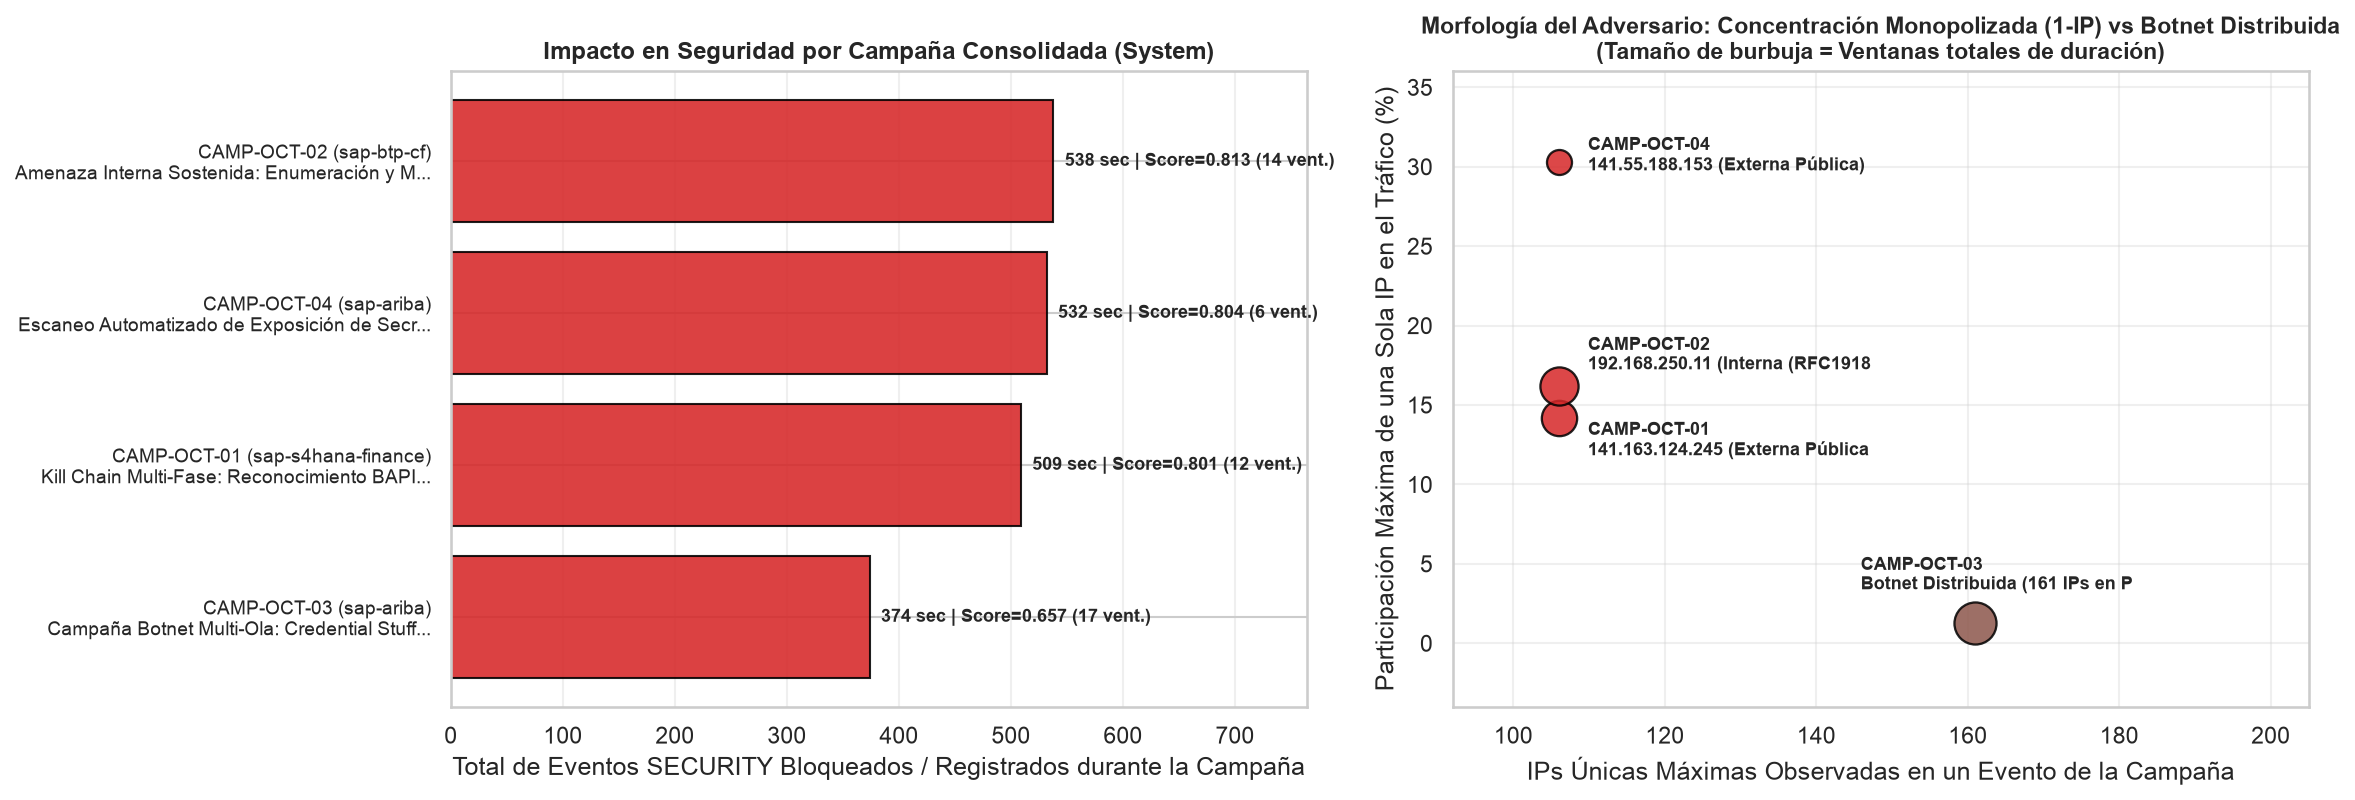

In [10]:
def correlacionar_campanas_soc(df_soc):
    """Fusiona eventos SOC del mismo día que comparten IP concentrada o mismo endpoint /auth/login."""
    soc = df_soc[df_soc['CATEGORIA_TRIAGE'].str.contains('SOC')].sort_values('INICIO').copy()
    usados = set()
    campanas = []
    camp_id = 1

    for idx, r in soc.iterrows():
        if r['EVENTO_ID'] in usados:
            continue
        grupo = [r]
        usados.add(r['EVENTO_ID'])

        for _, r2 in soc.iterrows():
            if r2['EVENTO_ID'] in usados:
                continue
            mismo_dia = r['INICIO'].date() == r2['INICIO'].date()
            misma_ip_fuerte = (r['TOP_IP'] == r2['TOP_IP']) and (r['TOP_IP_%'] >= 6.0) and (r2['TOP_IP_%'] >= 6.0)
            mismo_target_auth = (
                r['APP_OBJETIVO'] == r2['APP_OBJETIVO']
                and ('auth/login' in r['ENDPOINTS_CLAVE'])
                and ('auth/login' in r2['ENDPOINTS_CLAVE'])
            )
            if mismo_dia and (misma_ip_fuerte or mismo_target_auth):
                grupo.append(r2)
                usados.add(r2['EVENTO_ID'])

        g_df = pd.DataFrame(grupo)
        fases = ' -> '.join([f"[Ev#{int(x['EVENTO_ID'])} {x['INICIO']:%H:%M} UTC: {x['TIPO_ESPECIFICO']}]" for _, x in g_df.iterrows()])

        if len(g_df) > 1 and ('auth/login' in ' '.join(g_df['ENDPOINTS_CLAVE'])) and g_df['TOP_IP_%'].max() >= 8.0:
            nombre_campana = 'Kill Chain Multi-Fase: Reconocimiento BAPI -> Intrusión Auth y Escalada'
            mitre = 'TA0043 (Reconnaissance) -> TA0006 (Credential Access) -> TA0004 (Privilege Escalation)'
        elif g_df['IPS_UNICAS_EVENTO'].max() >= 130 and g_df['TOP_IP_%'].max() < 6.0:
            nombre_campana = 'Campaña Botnet Multi-Ola: Credential Stuffing & Posible Account Takeover'
            mitre = 'T1110.004 (Credential Stuffing) -> T1078 (Valid Accounts / Password Change)'
        elif (g_df['ORIGEN_IP'] == 'Interna (RFC1918)').any():
            nombre_campana = 'Amenaza Interna Sostenida: Enumeración y Movimiento Lateral REST/RFC'
            mitre = 'TA0007 (Discovery) -> TA0008 (Lateral Movement - Internal RFC1918)'
        elif '.git/config' in ' '.join(g_df['ENDPOINTS_CLAVE']):
            nombre_campana = 'Escaneo Automatizado de Exposición de Secretos (/.git/config) y Endpoints RFC'
            mitre = 'T1595.002 (Vulnerability Scanning) -> T1213 (Information Repositories)'
        else:
            nombre_campana = g_df.iloc[0]['TIPO_ESPECIFICO']
            mitre = 'TA0043 / TA0001 (Initial Access)'

        campanas.append({
            'CAMPANA_ID': f'CAMP-OCT-{camp_id:02d}',
            'EVENTOS_FUSIONADOS': [int(x) for x in g_df['EVENTO_ID'].tolist()],
            'N_OLAS': len(g_df),
            'VENTANAS_TOTALES': int(g_df['N_VENTANAS'].sum()),
            'INICIO_CAMPANA': g_df['INICIO'].min(),
            'FIN_CAMPANA': g_df['FIN'].max(),
            'SCORE_MAX': float(g_df['SCORE_PICO'].max()),
            'NOMBRE_CAMPANA': nombre_campana,
            'MITRE_ATTACK': mitre,
            'ACTOR_PRINCIPAL': f"{g_df.iloc[0]['TOP_IP']} ({g_df.iloc[0]['ORIGEN_IP']})" if g_df['TOP_IP_%'].max() >= 8.0 else f"Botnet Distribuida ({int(g_df['IPS_UNICAS_EVENTO'].max())} IPs en {g_df.iloc[0]['REGION_DOM']})",
            'MAX_IP_SHARE_%': float(g_df['TOP_IP_%'].max()),
            'REGION_ORIGEN': g_df.iloc[0]['REGION_DOM'],
            'APPS_AFECTADAS': ', '.join(g_df['APP_OBJETIVO'].unique()),
            'LOGS_TOTALES': int(g_df['LOGS_EVENTO'].sum()),
            'ALERTAS_SECURITY': int(g_df['LOGS_SECURITY'].sum()),
            'FASES_KILL_CHAIN': fases,
            'ENDPOINTS_CLAVE': ' ; '.join(g_df['ENDPOINTS_CLAVE'].unique()),
            'EVIDENCIA_CRUDA': ' || '.join(g_df['EVIDENCIA_FORENSE_LOGS'].unique()),
        })
        camp_id += 1

    return pd.DataFrame(campanas)

df_campanas = correlacionar_campanas_soc(df_clustered)

print("[ALERTA] CAMPAÑAS DE CIBERATAQUE CONSOLIDADAS EN OCTUBRE 2026 (LISTAS PARA REPORTES POSTMORTEM):")
display(df_campanas[[
    'CAMPANA_ID', 'EVENTOS_FUSIONADOS', 'N_OLAS', 'VENTANAS_TOTALES', 'SCORE_MAX',
    'NOMBRE_CAMPANA', 'ACTOR_PRINCIPAL', 'APPS_AFECTADAS', 'ALERTAS_SECURITY', 'MITRE_ATTACK'
]])

# --- GRÁFICA 6: RESUMEN EJECUTIVO DE LAS 4 CAMPAÑAS DE ATAQUE + MORFOLOGÍA DEL ADVERSARIO ---
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.5))

# Panel 1: Alertas SECURITY acumuladas y Score Máximo por Campaña
c_sorted = df_campanas.sort_values('ALERTAS_SECURITY', ascending=True)
y_pos = np.arange(len(c_sorted))
etiquetas_c = [f"{r['CAMPANA_ID']} ({r['APPS_AFECTADAS']})\n{r['NOMBRE_CAMPANA'][:42]}..." for _, r in c_sorted.iterrows()]

bars = axes[0].barh(y_pos, c_sorted['ALERTAS_SECURITY'], color='#d62728', alpha=0.88, edgecolor='black')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(etiquetas_c, fontsize=9)
axes[0].set_xlabel('Total de Eventos SECURITY Bloqueados / Registrados durante la Campaña')
axes[0].set_title('Impacto en Seguridad por Campaña Consolidada (System)', fontsize=11.5, fontweight='bold')
for bar, (_, r) in zip(bars, c_sorted.iterrows()):
    axes[0].text(
        bar.get_width() + 10, bar.get_y() + bar.get_height()/2,
        f"{int(r['ALERTAS_SECURITY'])} sec | Score={r['SCORE_MAX']:.3f} ({int(r['VENTANAS_TOTALES'])} vent.)",
        va='center', fontsize=8.8, fontweight='bold'
    )
axes[0].set_xlim(0, c_sorted['ALERTAS_SECURITY'].max() * 1.42)
axes[0].grid(axis='x', alpha=0.3)

# Panel 2: Firma de Origen (Concentración 1-IP vs Dispersión Botnet)
offsets_camp = {
    'CAMP-OCT-01': (14, -18),
    'CAMP-OCT-02': (14, 8),
    'CAMP-OCT-03': (-55, 16),
    'CAMP-OCT-04': (14, -4),
}
for _, r in df_campanas.iterrows():
    es_botnet = r['MAX_IP_SHARE_%'] < 6.0
    color_p = '#8c564b' if es_botnet else '#d62728'
    sub_evs = df_clustered[df_clustered['EVENTO_ID'].isin(r['EVENTOS_FUSIONADOS'])]
    max_uips = sub_evs['IPS_UNICAS_EVENTO'].max()
    axes[1].scatter(max_uips, r['MAX_IP_SHARE_%'], s=r['VENTANAS_TOTALES'] * 24, color=color_p, alpha=0.85, edgecolors='black', linewidths=1.1)
    dx, dy = offsets_camp.get(r['CAMPANA_ID'], (10, -4))
    axes[1].annotate(
        f"{r['CAMPANA_ID']}\n{r['ACTOR_PRINCIPAL'][:32]}",
        (max_uips, r['MAX_IP_SHARE_%']),
        xytext=(dx, dy), textcoords='offset points', fontsize=8.5, fontweight='bold'
    )

axes[1].set_title('Morfología del Adversario: Concentración Monopolizada (1-IP) vs Botnet Distribuida\n(Tamaño de burbuja = Ventanas totales de duración)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('IPs Únicas Máximas Observadas en un Evento de la Campaña')
axes[1].set_ylabel('Participación Máxima de una Sola IP en el Tráfico (%)')
axes[1].set_xlim(92, 205)
axes[1].set_ylim(-4, 36)
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [11]:
# --- EXPORTACIÓN DEL PAYLOAD ESTRUCTURADO PARA EL AGENTE FORENSE IA Y SAC ---
out_dir = 'outputs_octubre'
os.makedirs(out_dir, exist_ok=True)

llm_soc = reales_llm_full[reales_llm_full['CATEGORIA_TRIAGE'].str.contains('SOC')]
sre_all_sys = reales_sys_full[reales_sys_full['CATEGORIA_TRIAGE'].str.contains('SRE')]
sre_all_llm = reales_llm_full[reales_llm_full['CATEGORIA_TRIAGE'].str.contains('SRE')]

payload_forense = {
    'metadata_ejecucion': {
        'tabla_hana': TABLA_OCTUBRE,
        'periodo_analizado_utc': {'inicio': str(t0), 'fin': str(t_max)},
        'total_logs_procesados': total_logs,
        'configuracion_ventanas': {'tamano_seg': 300, 'paso_seg': 150, 'escalado_previo': 'HANA PAL FeatureNormalizer (Z-Score)', 'contaminacion_if': 0.01},
        'resumen_triage_alertas': {
            'alertas_crudas_if_eventos': int(len(ev_sys) + len(ev_llm)),
            'anomalias_comunes_descartadas': int((ev_sys['CATEGORIA_TRIAGE'] == '[Ruido] Anomalía Común').sum() + (ev_llm['CATEGORIA_TRIAGE'] == '[Ruido] Anomalía Común').sum()),
            'incidentes_operativos_sre': int(len(sre_all_sys) + len(sre_all_llm)),
            'campanas_ciberataque_soc_system': int(len(df_campanas)),
            'rafagas_prompt_injection_soc_llm': int(len(llm_soc)),
            'tasa_reduccion_ruido_pct': round(100.0 * (1.0 - (len(df_campanas) + len(llm_soc) + len(sre_all_sys) + len(sre_all_llm)) / (len(ev_sys) + len(ev_llm))), 1)
        },
        'metricas_clustering_pal_kmeans': {
            'k_clusters': 3,
            'cosine_intra_cluster_mean': round(mean_intra, 4),
            'cosine_inter_cluster_mean': round(mean_inter, 4),
            'silhouette_cosine': round(mean_sil, 4)
        }
    },
    'campanas_criticas_soc_para_postmortem': [
        {
            'campana_id': r['CAMPANA_ID'],
            'nombre_campana': r['NOMBRE_CAMPANA'],
            'mitre_attack_mapping': r['MITRE_ATTACK'],
            'linea_tiempo_utc': {'inicio': str(r['INICIO_CAMPANA']), 'fin': str(r['FIN_CAMPANA']), 'olas_detectadas': int(r['N_OLAS']), 'ventanas_5min_afectadas': int(r['VENTANAS_TOTALES'])},
            'severidad_score_if': round(float(r['SCORE_MAX']), 4),
            'actor_amenaza': r['ACTOR_PRINCIPAL'],
            'region_origen': r['REGION_ORIGEN'],
            'componentes_sap_afectados': r['APPS_AFECTADAS'],
            'endpoints_atacados': r['ENDPOINTS_CLAVE'],
            'volumen_impacto': {'logs_totales_ventana': int(r['LOGS_TOTALES']), 'alertas_security': int(r['ALERTAS_SECURITY']), 'concentracion_max_ip_pct': float(r['MAX_IP_SHARE_%'])},
            'secuencia_fases': r['FASES_KILL_CHAIN'],
            'evidencia_forense_mensajes': r['EVIDENCIA_CRUDA']
        }
        for _, r in df_campanas.sort_values('SCORE_MAX', ascending=False).iterrows()
    ],
    'sondeos_adversariales_llm_soc': [
        {
            'evento_id': int(r['EVENTO_ID']),
            'timestamp_utc': str(r['INICIO']),
            'tipo': r['TIPO_ESPECIFICO'],
            'injections_bloqueadas_5min': int(r['INJECTIONS_BLOQ']),
            'ratio_injection': float(r['RATIO_INJ_PICO']),
            'modelo_principal_objetivo': r['PROVEEDOR_MODELO_TOP'],
            'evidencia_guardrail': r['EVIDENCIA_FORENSE_LOGS']
        }
        for _, r in llm_soc.iterrows()
    ],
    'incidentes_operativos_sre_observabilidad': {
        'system_disponibilidad': [
            {
                'evento_id': int(r['EVENTO_ID']),
                'inicio_utc': str(r['INICIO']),
                'fin_utc': str(r['FIN']),
                'app_afectada': r['APP_OBJETIVO'],
                'region': r['REGION_DOM'],
                'diagnostico': r['TIPO_ESPECIFICO'],
                'tasa_5xx_pico': float(r['ERR_500_PICO']),
                'evidencia_sre': r['EVIDENCIA_FORENSE_LOGS']
            }
            for _, r in sre_all_sys.iterrows()
        ],
        'llm_latencia_timeouts': [
            {
                'evento_id': int(r['EVENTO_ID']),
                'inicio_utc': str(r['INICIO']),
                'ventanas': int(r['N_VENTANAS']),
                'timeouts_30s': int(r['TIMEOUTS_30S']),
                'latencia_media_ms': float(r['RESP_MS_PICO']),
                'diagnostico': r['TIPO_ESPECIFICO']
            }
            for _, r in sre_all_llm.iterrows()
        ]
    }
}

json_path = os.path.join(out_dir, 'payload_forense_octubre_2026.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(payload_forense, f, ensure_ascii=False, indent=2)

# Limpiar tablas temporales de sesión en HANA y cerrar conexión limpiamente
ventanas.drop_temp(conn, '#WIN_SYSTEM')
ventanas.drop_temp(conn, '#WIN_LLM')
ventanas.drop_temp(conn, 'TMP_ISAAC_SYS_EVENTS_L2')

print(f"[OK] Payload JSON exportado exitosamente en: {os.path.abspath(json_path)}")
print("\n[JSON] VISTA PREVIA DEL RESUMEN EJECUTIVO EN EL PAYLOAD PARA EL AGENTE IA:")
print(json.dumps(payload_forense['metadata_ejecucion'], indent=2, ensure_ascii=False))
print("\n[JSON] CAMPAÑA #1 (MAYOR SCORE) LISTA PARA REPORTE POSTMORTEM:")
print(json.dumps(payload_forense['campanas_criticas_soc_para_postmortem'][0], indent=2, ensure_ascii=False))

[OK] Payload JSON exportado exitosamente en: /Users/isaacmartinez/Documents/BloqueAD26/RetoSAP/sandbox/outputs_octubre/payload_forense_octubre_2026.json

[JSON] VISTA PREVIA DEL RESUMEN EJECUTIVO EN EL PAYLOAD PARA EL AGENTE IA:
{
  "tabla_hana": "LOGS_2026_10",
  "periodo_analizado_utc": {
    "inicio": "2026-10-01 00:00:00",
    "fin": "2026-10-11 23:59:59"
  },
  "total_logs_procesados": 3748811,
  "configuracion_ventanas": {
    "tamano_seg": 300,
    "paso_seg": 150,
    "escalado_previo": "HANA PAL FeatureNormalizer (Z-Score)",
    "contaminacion_if": 0.01
  },
  "resumen_triage_alertas": {
    "alertas_crudas_if_eventos": 73,
    "anomalias_comunes_descartadas": 57,
    "incidentes_operativos_sre": 6,
    "campanas_ciberataque_soc_system": 4,
    "rafagas_prompt_injection_soc_llm": 4,
    "tasa_reduccion_ruido_pct": 80.8
  },
  "metricas_clustering_pal_kmeans": {
    "k_clusters": 3,
    "cosine_intra_cluster_mean": 0.8843,
    "cosine_inter_cluster_mean": 0.2351,
    "silhouett